# RegeneraRS: gráficos e estatísticas descritivas

Este notebook lê o arquivo `RegeneraRS_merge_limpo(2).xlsx` e produz gráficos correspondentes aos indicadores do **Relatório Anual RegeneraRS, julho de 2024 a julho de 2025**. As figuras do relatório foram conferidas nas páginas 13, 25–28, 48 e 51.

Os cálculos usam os dados da planilha. Os números transcritos do PDF aparecem com a indicação **Relatório 2025**. O Excel não informa uma data de corte para os valores operacionais; portanto, os gráficos não são apresentados como resultados de um ano específico nem como uma evolução em relação a 2025.

## Como executar

1. Coloque o notebook e a planilha na mesma pasta.
2. Abra o notebook no Jupyter ou no VS Code e selecione um ambiente Python.
3. Confira o nome do arquivo na célula de configuração e execute todas as células, na ordem.

Se necessário, instale as dependências no ambiente escolhido:

```bash
python -m pip install jupyterlab pandas numpy matplotlib openpyxl
```

A execução não consulta a internet e não precisa do PDF. As referências do relatório estão documentadas no próprio notebook. Gráficos em PNG e PDF e tabelas em CSV UTF-8 tabulado e Excel são gravados em `resultados_regenerars`, na pasta da planilha.


## Critérios de cálculo

- **Linhas e projetos:** a aba `Merge` contém repetições por município. Valores financeiros e vidas alcançadas são consolidados por `Codigo` e `Proyecto`, após conferir se os números são iguais dentro de cada grupo. PRJ-019 tem dois subprojetos e ambos são preservados.
- **Contagem de projetos:** os códigos são contados uma vez. A planilha inclui iniciativas e organizações intermediárias; a quantidade de códigos cadastrados não equivale, por si só, à quantidade de projetos aprovados do PDF.
- **Ausências:** células vazias continuam ausentes. Uma soma com registros sem informação é identificada como subtotal conhecido. Zeros registrados são mantidos.
- **Municípios:** o vínculo territorial não informa a distribuição de dinheiro ou pessoas entre municípios. Não são calculados gastos municipais a partir dos totais dos projetos.
- **Pessoas:** as vidas alcançadas são somadas entre unidades distintas. Sem identificadores individuais, não é possível descontar pessoas atendidas por mais de um projeto.
- **FINBRA/SICONFI:** cada município é contado uma vez. As 88 estatísticas já existentes vêm exclusivamente de `desc_municipality`, do arquivo de origem de 2023–2025. `__mean` é uma média temporal; as estatísticas calculadas neste notebook descrevem sua distribuição entre municípios.
- **Classificação:** a planilha não contém eixos nem status em campos próprios. Há um mapa editável de eixos apoiado nas páginas do PDF. Classificações sugeridas pela leitura dos textos ficam desativadas por padrão. Status históricos não são transferidos para o período da planilha.
- **Organizações intermediárias:** os totais incluem os registros financeiros disponíveis, conforme a planilha. Se algum registro resumir valores também presentes em projetos individuais, será necessário excluir essa sobreposição na configuração abaixo.


In [1]:
from pathlib import Path
import hashlib
import json
import platform
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

NOME_PLANILHA = "RegeneraRS_merge_limpo(2).xlsx"
PASTA = Path.cwd()
NOME_PASTA_RESULTADOS = "resultados_regenerars"

# Altere somente após conferir a classificação sugerida na seção de eixos.
USAR_EIXOS_SUGERIDOS = False
AJUSTES_EIXOS = {}      # Exemplo: {"PRJ-002": "Soluções urbanas"}
STATUS_ATUAIS = {}      # Exemplo: {"PRJ-001": "Em implementação"}
TESES_ATUAIS = {}       # Valores aceitos são documentados na seção de teses.
CODIGOS_EXCLUIR_ANALISE = []   # Exclusões também são registradas nas tabelas exportadas.

ORDEM_EIXOS = ["Educação", "Habitação", "Apoio a negócios", "Soluções urbanas", "Sem classificação"]
CORES_EIXOS = {"Educação": "#F56B2D", "Habitação": "#9D8064",
               "Apoio a negócios": "#8A9E39", "Soluções urbanas": "#006D53",
               "Sem classificação": "#98A0A8"}
VERDE = "#005F49"
LARANJA = "#F56B2D"
CINZA = "#5B6570"

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.labelcolor": "#263238",
                     "text.color": "#263238", "figure.facecolor": "white",
                     "savefig.facecolor": "white", "figure.dpi": 110})
pd.set_option("display.max_columns", 18)
pd.set_option("display.max_rows", 45)

TABELAS = {}
FIGURAS = []

def numero_pt(valor, casas=0):
    if pd.isna(valor):
        return "Sem informação"
    return f"{valor:,.{casas}f}".replace(",", "_").replace(".", ",").replace("_", ".")

def nome_seguro(texto):
    texto = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-zA-Z0-9]+", "_", texto).strip("_").lower()

def tabela(nome, dados, mostrar=True):
    dados = dados.copy()
    TABELAS[nome] = dados
    if mostrar:
        display(dados)
    return dados

def salvar_figura(fig, nome, nota):
    fig.text(0.02, 0.015, nota, ha="left", va="bottom", fontsize=8, color=CINZA)
    fig.tight_layout(rect=(0, 0.09, 1, 0.95))
    base = PASTA_SAIDA / nome_seguro(nome)
    fig.savefig(base.with_suffix(".png"), dpi=300, bbox_inches="tight")
    fig.savefig(base.with_suffix(".pdf"), bbox_inches="tight")
    FIGURAS.append({"nome": nome, "png": base.name + ".png", "pdf": base.name + ".pdf", "nota": nota})
    plt.show()
    plt.close(fig)

def estatisticas_descritivas(dados, colunas):
    resultado = dados[colunas].describe(percentiles=[0.25, 0.50, 0.75]).T
    resultado = resultado.rename(columns={"count": "n", "mean": "média", "std": "desvio_padrão",
                                          "min": "mínimo", "25%": "Q1", "50%": "mediana",
                                          "75%": "Q3", "max": "máximo"})
    resultado["ausentes"] = dados[colunas].isna().sum()
    resultado["zeros"] = dados[colunas].eq(0).sum()
    resultado["soma_conhecida"] = dados[colunas].sum(min_count=1)
    return resultado.reset_index(names="variável")


## Leitura do Excel

O nome configurado tem prioridade. Se ele não existir, o código procura uma única planilha cujo nome comece com `RegeneraRS_merge_limpo`. Havendo mais de uma candidata, é preciso indicar o nome desejado. A aba `Revision` é consultada para documentação; seus textos não são usados como observações nos cálculos.


In [2]:
arquivo = PASTA / NOME_PLANILHA
if not arquivo.is_file():
    candidatas = sorted(p for p in PASTA.glob("RegeneraRS_merge_limpo*.xlsx") if not p.name.startswith("~$"))
    if len(candidatas) == 1:
        arquivo = candidatas[0]
    else:
        nomes = [p.name for p in candidatas]
        raise FileNotFoundError(f"Indique NOME_PLANILHA. Arquivo configurado não encontrado. Candidatas: {nomes}")

PASTA_SAIDA = arquivo.parent / NOME_PASTA_RESULTADOS
PASTA_SAIDA.mkdir(exist_ok=True)
excel = pd.ExcelFile(arquivo, engine="openpyxl")
abas_obrigatorias = {"Merge", "Municipios"}
if not abas_obrigatorias.issubset(excel.sheet_names):
    raise ValueError(f"A planilha precisa das abas {sorted(abas_obrigatorias)}. Encontradas: {excel.sheet_names}")

base = pd.read_excel(excel, sheet_name="Merge")
municipios = pd.read_excel(excel, sheet_name="Municipios")
revisao = pd.read_excel(excel, sheet_name="Revision", header=None) if "Revision" in excel.sheet_names else pd.DataFrame()
excel.close()

CAMPOS_FINANCEIROS = ["ValorAporteRegenera", "ValorTotalPrevisto", "ValorTotalActual", "ValorMobilizado", "ValorEjecutado"]
CAMPOS_VIDAS = ["VidasDiretas", "VidasIndiretas"]
CAMPOS_QUANTITATIVOS = CAMPOS_FINANCEIROS + CAMPOS_VIDAS
METRICAS_FISCAIS = ["Population", "Rec Tributária", "Rec Correntes", "Cota FPM", "FNAS", "ISSQN",
                   "TaxRevenuePC", "FiscalAutonomy", "FNAS_PC", "FPMDependency", "ISSQN_PC"]
SUFIXOS = ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
CAMPOS_FISCAIS = [f"{metrica}__{sufixo}" for metrica in METRICAS_FISCAIS for sufixo in SUFIXOS]
CAMPOS_MEDIAS_FISCAIS = [f"{metrica}__mean" for metrica in METRICAS_FISCAIS]

obrigatorias_merge = ["Codigo", "Proyecto", "Municipios", "municipality_code_7", "municipality_code_6"] + CAMPOS_QUANTITATIVOS + CAMPOS_FISCAIS
obrigatorias_municipios = ["Municipio", "municipality_code_7", "municipality_code_6"] + CAMPOS_FISCAIS
for nome, dados, colunas in [("Merge", base, obrigatorias_merge), ("Municipios", municipios, obrigatorias_municipios)]:
    faltantes = sorted(set(colunas) - set(dados.columns))
    if faltantes:
        raise ValueError(f"Colunas ausentes na aba {nome}: {faltantes}")
    for coluna in [c for c in colunas if c in CAMPOS_QUANTITATIVOS + CAMPOS_FISCAIS]:
        dados[coluna] = pd.to_numeric(dados[coluna], errors="raise")
    for coluna, digitos in [("municipality_code_7", 7), ("municipality_code_6", 6)]:
        valores = pd.to_numeric(dados[coluna], errors="raise")
        validos = valores.dropna()
        if not (validos.mod(1).eq(0).all() and validos.between(10**(digitos-1), 10**digitos-1).all()):
            raise ValueError(f"Códigos inválidos em {nome}.{coluna}")
        dados[coluna] = valores.astype("Int64")

for coluna in ["Codigo", "Proyecto"]:
    base[coluna] = base[coluna].astype("string").str.strip()
    if base[coluna].isna().any() or base[coluna].eq("").any():
        raise ValueError(f"Há registros sem {coluna}; confira a planilha antes de agregar.")
if municipios["municipality_code_7"].isna().any() or municipios["municipality_code_7"].duplicated().any():
    raise ValueError("A aba Municipios precisa ter uma única linha por código municipal válido.")
if not municipios["municipality_code_7"].astype(str).str[:6].eq(municipios["municipality_code_6"].astype(str)).all():
    raise ValueError("Há incompatibilidade entre códigos municipais de seis e sete dígitos.")

sha256 = hashlib.sha256(arquivo.read_bytes()).hexdigest()
print(f"Planilha: {arquivo.name}")
print(f"Merge: {len(base)} linhas; Municipios: {len(municipios)} municípios.")
print(f"Pasta de saída: {NOME_PASTA_RESULTADOS}")


Planilha: RegeneraRS_merge_limpo.xlsx
Merge: 438 linhas; Municipios: 497 municípios.
Pasta de saída: resultados_regenerars


## Consolidação e revisão do pareamento

Uma divergência numérica entre linhas da mesma unidade interrompe o cálculo, em vez de escolher arbitrariamente uma linha. O bloco fiscal de cada linha é comparado com o município correspondente na aba `Municipios`. São verificadas também as posições dos códigos de seis e sete dígitos.


In [3]:
CHAVE_UNIDADE = ["Codigo", "Proyecto"]
distintos = base.groupby(CHAVE_UNIDADE, dropna=False)[CAMPOS_QUANTITATIVOS].nunique(dropna=True)
conflitos = distintos.stack().loc[lambda s: s.gt(1)].rename("valores_distintos").reset_index()
if not conflitos.empty:
    display(conflitos)
    raise ValueError("Há valores conflitantes dentro do mesmo código e título. Revise as unidades indicadas.")

colunas_metadados = [c for c in ["ProyectoDescripcion", "Organizacion", "Entrada", "Resumen", "IndicadoresClave"] if c in base]
unidades = base.groupby(CHAVE_UNIDADE, sort=False, dropna=False)[CAMPOS_QUANTITATIVOS + colunas_metadados].first().reset_index()
unidades["tem_dados_quantitativos"] = unidades[CAMPOS_QUANTITATIVOS].notna().any(axis=1)
unidades["unidade_id"] = unidades["Codigo"] + " | " + unidades["Proyecto"]

vinculos = base.loc[base["municipality_code_7"].notna(), CHAVE_UNIDADE + ["municipality_code_7"]].drop_duplicates()
vinculos_codigo = vinculos[["Codigo", "municipality_code_7"]].drop_duplicates()
chaves_fiscais = municipios.set_index("municipality_code_7")
linhas_com_municipio = base.loc[base["municipality_code_7"].notna()]
sem_referencia = set(linhas_com_municipio["municipality_code_7"]) - set(chaves_fiscais.index)
if sem_referencia:
    raise ValueError(f"Municípios do Merge sem referência na aba Municipios: {sorted(sem_referencia)}")
esperados = chaves_fiscais.loc[linhas_com_municipio["municipality_code_7"], CAMPOS_FISCAIS].to_numpy(dtype=float)
observados = linhas_com_municipio[CAMPOS_FISCAIS].to_numpy(dtype=float)
if not np.isclose(observados, esperados, rtol=1e-10, atol=1e-8, equal_nan=True).all():
    raise ValueError("Há estatísticas fiscais divergentes do município de referência.")
codigo_6_esperado = chaves_fiscais.loc[linhas_com_municipio["municipality_code_7"], "municipality_code_6"].to_numpy()
if not np.array_equal(linhas_com_municipio["municipality_code_6"].to_numpy(), codigo_6_esperado):
    raise ValueError("Há código municipal de seis dígitos divergente do município de referência.")
if base.loc[base["municipality_code_7"].isna(), CAMPOS_FISCAIS].notna().any().any():
    raise ValueError("Há dados fiscais em uma linha sem código municipal.")

desconhecidos_exclusao = set(CODIGOS_EXCLUIR_ANALISE) - set(unidades["Codigo"])
if desconhecidos_exclusao:
    raise ValueError(f"Códigos de exclusão inexistentes: {sorted(desconhecidos_exclusao)}")
unidades_analise = unidades.loc[~unidades["Codigo"].isin(CODIGOS_EXCLUIR_ANALISE)].copy()
vinculos_analise = vinculos_codigo.loc[~vinculos_codigo["Codigo"].isin(CODIGOS_EXCLUIR_ANALISE)].copy()
codigos_listados = set(vinculos_analise["municipality_code_7"])
municipios["com_projeto_listado"] = municipios["municipality_code_7"].isin(codigos_listados)
contagem_municipal = vinculos_analise.groupby("municipality_code_7")["Codigo"].nunique()
municipios["codigos_listados_na_analise"] = municipios["municipality_code_7"].map(contagem_municipal).fillna(0).astype(int)
municipios["grupo_territorial"] = np.where(municipios["com_projeto_listado"], "Com projeto listado", "Sem projeto listado")

controle = pd.DataFrame([
    ("Linhas na aba Merge", len(base)),
    ("Códigos cadastrados", base["Codigo"].nunique()),
    ("Unidades distintas por código e título", len(unidades)),
    ("Unidades com algum dado quantitativo", int(unidades["tem_dados_quantitativos"].sum())),
    ("Códigos com algum dado quantitativo", unidades.loc[unidades["tem_dados_quantitativos"], "Codigo"].nunique()),
    ("Unidades sem qualquer dado quantitativo", int((~unidades["tem_dados_quantitativos"]).sum())),
    ("Linhas com município e bloco fiscal conferido", len(linhas_com_municipio)),
    ("Municípios distintos nos vínculos da análise", len(codigos_listados)),
    ("Municípios no contexto FINBRA/SICONFI", len(municipios)),
    ("Códigos excluídos da análise", len(CODIGOS_EXCLUIR_ANALISE))
], columns=["controle", "quantidade"])
tabela("controle_base", controle)
tabela("unidades_excluidas", unidades.loc[unidades["Codigo"].isin(CODIGOS_EXCLUIR_ANALISE)], mostrar=False)
tabela("registros_sem_municipio", base.loc[base["municipality_code_7"].isna(), ["Codigo", "Proyecto", "Entrada"]].drop_duplicates())


,controle,quantidade
0,Linhas na aba Merge,438
1,Códigos cadastrados,39
2,Unidades distintas por código e título,40
3,Unidades com algum dado quantitativo,23
4,Códigos com algum dado quantitativo,22
5,Unidades sem qualquer dado quantitativo,17
6,Linhas com município e bloco fiscal conferido,420
7,Municípios distintos nos vínculos da análise,226
8,Municípios no contexto FINBRA/SICONFI,497
9,Códigos excluídos da análise,0


,Codigo,Proyecto,Entrada
387,PRJ-037,CoalizãoRS (Organização intermediária),388.0
421,PRJ-021,Fundo de Melhorias Habitacionais para Áreas Em...,NaN
422,PRJ-022,Refundar Educação no Rio Grande do Sul,NaN
423,PRJ-023,S.O.S De Volta para Escola,NaN
424,PRJ-024,SuperaRS,NaN
425,PRJ-025,2 por 1,NaN
426,PRJ-026,Transforma Realidades - Apoio ao Aprimoramento...,NaN
427,PRJ-027,Futuro do Vale,NaN
428,PRJ-028,Fundo Resiliência,NaN
429,PRJ-029,Teia de Soluções II,NaN


,Codigo,Proyecto,Entrada
387,PRJ-037,CoalizãoRS (Organização intermediária),388.0
421,PRJ-021,Fundo de Melhorias Habitacionais para Áreas Em...,NaN
422,PRJ-022,Refundar Educação no Rio Grande do Sul,NaN
423,PRJ-023,S.O.S De Volta para Escola,NaN
424,PRJ-024,SuperaRS,NaN
425,PRJ-025,2 por 1,NaN
426,PRJ-026,Transforma Realidades - Apoio ao Aprimoramento...,NaN
427,PRJ-027,Futuro do Vale,NaN
428,PRJ-028,Fundo Resiliência,NaN
429,PRJ-029,Teia de Soluções II,NaN


In [4]:
cobertura = pd.DataFrame({"variável": CAMPOS_QUANTITATIVOS})
cobertura["unidades_no_cadastro"] = len(unidades_analise)
cobertura["unidades_com_valor"] = [unidades_analise[c].notna().sum() for c in CAMPOS_QUANTITATIVOS]
cobertura["unidades_sem_valor"] = len(unidades_analise) - cobertura["unidades_com_valor"]
cobertura["cobertura_percentual"] = 100 * cobertura["unidades_com_valor"] / max(len(unidades_analise), 1)
cobertura["subtotal_conhecido"] = [unidades_analise[c].sum(min_count=1) for c in CAMPOS_QUANTITATIVOS]
tabela("cobertura_quantitativa", cobertura)

alertas = []
for _, row in unidades_analise.iterrows():
    for c in CAMPOS_QUANTITATIVOS:
        if pd.notna(row[c]) and row[c] < 0:
            alertas.append((row["Codigo"], row["Proyecto"], c, row[c], "Valor negativo: conferir a fonte."))
    if pd.notna(row["ValorTotalActual"]) and pd.notna(row["ValorEjecutado"]) and row["ValorEjecutado"] > row["ValorTotalActual"]:
        alertas.append((row["Codigo"], row["Proyecto"], "ValorEjecutado", row["ValorEjecutado"],
                        f"Execução superior ao total atual informado ({numero_pt(row['ValorTotalActual'], 2)})."))
    if row["ValorAporteRegenera"] == 0 and pd.notna(row["ValorMobilizado"]) and row["ValorMobilizado"] > 0:
        alertas.append((row["Codigo"], row["Proyecto"], "ValorAporteRegenera", 0,
                        "Aporte zero com mobilização positiva; razão individual de alavancagem indefinida."))
tabela("alertas_projetos", pd.DataFrame(alertas, columns=["Codigo", "Proyecto", "campo", "valor", "observação"]))

fiscais_alertas = []
for c in ["FiscalAutonomy__mean", "FPMDependency__mean"]:
    for _, row in municipios.loc[municipios[c].lt(0) | municipios[c].gt(1)].iterrows():
        fiscais_alertas.append((row["municipality_code_7"], row["Municipio"], c, row[c],
                                "Proporção fora do intervalo 0–1. Conferir definição e dados; valor mantido."))
tabela("alertas_fiscais", pd.DataFrame(fiscais_alertas, columns=["municipality_code_7", "Municipio", "campo", "valor", "observação"]))


,variável,unidades_no_cadastro,unidades_com_valor,unidades_sem_valor,cobertura_percentual,subtotal_conhecido
0,ValorAporteRegenera,40,23,17,57.5,1.920907e+07
1,ValorTotalPrevisto,40,23,17,57.5,2.558976e+08
2,ValorTotalActual,40,21,19,52.5,1.872343e+08
3,ValorMobilizado,40,23,17,57.5,1.707264e+08
4,ValorEjecutado,40,21,19,52.5,2.828678e+07
5,VidasDiretas,40,23,17,57.5,6.268100e+04
6,VidasIndiretas,40,22,18,55.0,4.456530e+05


,Codigo,Proyecto,campo,valor,observação
0,PRJ-009,Fundo Reconstruir RS: Chamada de Projetos para...,ValorEjecutado,2308358.41,Execução superior ao total atual informado (2....
1,PRJ-010,Encanta Hub,ValorEjecutado,1159599.50,"Execução superior ao total atual informado (0,..."
2,PRJ-016,Programa de Saude Mental,ValorEjecutado,296250.00,"Execução superior ao total atual informado (0,..."
3,PRJ-019,Teia de Solucoes I — Tamanduá Caminhos Vivos,ValorAporteRegenera,0.00,Aporte zero com mobilização positiva; razão in...


,municipality_code_7,Municipio,campo,valor,observação
0,4300661,André da Rocha,FPMDependency__mean,1.135320,Proporção fora do intervalo 0–1. Conferir defi...
1,4301073,Arroio do Padre,FPMDependency__mean,1.049242,Proporção fora do intervalo 0–1. Conferir defi...
2,4302055,Benjamin Constant do Sul,FPMDependency__mean,1.132337,Proporção fora do intervalo 0–1. Conferir defi...
3,4302378,Bom Progresso,FPMDependency__mean,1.143902,Proporção fora do intervalo 0–1. Conferir defi...
4,4302584,Bozano,FPMDependency__mean,1.075180,Proporção fora do intervalo 0–1. Conferir defi...
...,...,...,...,...,...
49,4322376,Unistalda,FPMDependency__mean,1.076009,Proporção fora do intervalo 0–1. Conferir defi...
50,4322350,União da Serra,FPMDependency__mean,1.179260,Proporção fora do intervalo 0–1. Conferir defi...
51,4322558,Vanini,FPMDependency__mean,1.100095,Proporção fora do intervalo 0–1. Conferir defi...
52,4323507,Vista Alegre,FPMDependency__mean,1.018166,Proporção fora do intervalo 0–1. Conferir defi...


,municipality_code_7,Municipio,campo,valor,observação
0,4300661,André da Rocha,FPMDependency__mean,1.135320,Proporção fora do intervalo 0–1. Conferir defi...
1,4301073,Arroio do Padre,FPMDependency__mean,1.049242,Proporção fora do intervalo 0–1. Conferir defi...
2,4302055,Benjamin Constant do Sul,FPMDependency__mean,1.132337,Proporção fora do intervalo 0–1. Conferir defi...
3,4302378,Bom Progresso,FPMDependency__mean,1.143902,Proporção fora do intervalo 0–1. Conferir defi...
4,4302584,Bozano,FPMDependency__mean,1.075180,Proporção fora do intervalo 0–1. Conferir defi...
...,...,...,...,...,...
49,4322376,Unistalda,FPMDependency__mean,1.076009,Proporção fora do intervalo 0–1. Conferir defi...
50,4322350,União da Serra,FPMDependency__mean,1.179260,Proporção fora do intervalo 0–1. Conferir defi...
51,4322558,Vanini,FPMDependency__mean,1.100095,Proporção fora do intervalo 0–1. Conferir defi...
52,4323507,Vista Alegre,FPMDependency__mean,1.018166,Proporção fora do intervalo 0–1. Conferir defi...


## Correspondência com o relatório

O valor executado dos projetos não identifica quanto foi desembolsado pelo RegeneraRS. Também não há uma coluna que separe vidas projetadas de vidas já alcançadas. Por isso, as séries financeiras e de pessoas são nomeadas conforme os campos efetivamente disponíveis.

A página 51 repete indicadores das páginas anteriores. O desenho do estado no PDF é ilustrativo; ele não é um mapa de distribuição municipal dos recursos.


In [5]:
correspondencia = pd.DataFrame([
    ("13", "Tese de investimento 70% / 30%", "Meta transcrita do PDF; execução atual opcional", "Falta classificação por tese de investimento."),
    ("25 e 51", "Indicadores financeiros, projetos e cidades", "Painel e tabelas com dados da planilha", "Aporte e execução não equivalem automaticamente a deliberação e desembolso."),
    ("25 e 51", "Múltiplos de alavancagem", "Razões indicativas em amostras pareadas", "Confirmar que ValorMobilizado e ValorTotalPrevisto correspondem ao numerador do relatório."),
    ("25 e 51", "Aportes por eixo temático", "Roscas do relatório e da planilha", "Mapa editável de eixos; categorias ausentes ficam sem classificação."),
    ("26–27", "Status dos projetos aprovados", "Barras históricas; gráfico atual opcional", "Falta status atual em campo estruturado; cadastro não confirma aprovação."),
    ("28", "Vidas por eixo", "Barras, bolhas e estatísticas da planilha", "VidasDiretas e VidasIndiretas não identificam projeção nem pessoas únicas."),
    ("28 e 51", "Escolas, casas, empregos e demais entregas", "Tabela histórica e campos para atualização", "Indicadores atuais constam em textos livres; não são extraídos automaticamente."),
    ("48", "Participação dos veículos de mídia", "Pizza histórica transcrita do PDF", "A planilha não contém publicações, alcance ou valor publicitário."),
    ("Complemento", "Municípios e contexto fiscal", "Distribuições, comparação descritiva e tabelas", "FINBRA/SICONFI agregado; não são estimativas de efeito do programa.")
], columns=["páginas_pdf", "gráfico_ou_indicador", "saída_no_notebook", "limite_dos_dados"])
tabela("correspondencia_pdf", correspondencia)


,páginas_pdf,gráfico_ou_indicador,saída_no_notebook,limite_dos_dados
0,13,Tese de investimento 70% / 30%,Meta transcrita do PDF; execução atual opcional,Falta classificação por tese de investimento.
1,25 e 51,"Indicadores financeiros, projetos e cidades",Painel e tabelas com dados da planilha,Aporte e execução não equivalem automaticament...
2,25 e 51,Múltiplos de alavancagem,Razões indicativas em amostras pareadas,Confirmar que ValorMobilizado e ValorTotalPrev...
3,25 e 51,Aportes por eixo temático,Roscas do relatório e da planilha,Mapa editável de eixos; categorias ausentes fi...
4,26–27,Status dos projetos aprovados,Barras históricas; gráfico atual opcional,Falta status atual em campo estruturado; cadas...
5,28,Vidas por eixo,"Barras, bolhas e estatísticas da planilha",VidasDiretas e VidasIndiretas não identificam ...
6,28 e 51,"Escolas, casas, empregos e demais entregas",Tabela histórica e campos para atualização,Indicadores atuais constam em textos livres; n...
7,48,Participação dos veículos de mídia,Pizza histórica transcrita do PDF,"A planilha não contém publicações, alcance ou ..."
8,Complemento,Municípios e contexto fiscal,"Distribuições, comparação descritiva e tabelas",FINBRA/SICONFI agregado; não são estimativas d...


,páginas_pdf,gráfico_ou_indicador,saída_no_notebook,limite_dos_dados
0,13,Tese de investimento 70% / 30%,Meta transcrita do PDF; execução atual opcional,Falta classificação por tese de investimento.
1,25 e 51,"Indicadores financeiros, projetos e cidades",Painel e tabelas com dados da planilha,Aporte e execução não equivalem automaticament...
2,25 e 51,Múltiplos de alavancagem,Razões indicativas em amostras pareadas,Confirmar que ValorMobilizado e ValorTotalPrev...
3,25 e 51,Aportes por eixo temático,Roscas do relatório e da planilha,Mapa editável de eixos; categorias ausentes fi...
4,26–27,Status dos projetos aprovados,Barras históricas; gráfico atual opcional,Falta status atual em campo estruturado; cadas...
5,28,Vidas por eixo,"Barras, bolhas e estatísticas da planilha",VidasDiretas e VidasIndiretas não identificam ...
6,28 e 51,"Escolas, casas, empregos e demais entregas",Tabela histórica e campos para atualização,Indicadores atuais constam em textos livres; n...
7,48,Participação dos veículos de mídia,Pizza histórica transcrita do PDF,"A planilha não contém publicações, alcance ou ..."
8,Complemento,Municípios e contexto fiscal,"Distribuições, comparação descritiva e tabelas",FINBRA/SICONFI agregado; não são estimativas d...


## Eixos temáticos

O mapa abaixo usa os ícones e listas das páginas 26–27 do PDF para os projetos com correspondência identificável. PRJ-019 mantém o eixo de Teia de Soluções para os dois subprojetos, mas seus valores não são fundidos.

Há também sugestões de classificação apoiadas nas descrições e atividades do Excel. Elas servem para revisão e só entram nos gráficos se `USAR_EIXOS_SUGERIDOS = True`. Projetos sem evidência suficiente, fundos com várias frentes e organizações intermediárias permanecem sem classificação. Para corrigir um caso, informe seu código em `AJUSTES_EIXOS`.


In [6]:
# A classificação do relatório é usada como referência, não como status atual.
EIXOS_PDF = {
    "PRJ-001": ("Educação", "PDF 2025, p. 27: Escolas Indígenas"),
    "PRJ-003": ("Educação", "PDF 2025, p. 27: formação de lideranças / Centro Lemann"),
    "PRJ-005": ("Educação", "PDF 2025, p. 26: Ensino Médio Integral que Reconstrói"),
    "PRJ-006": ("Soluções urbanas", "PDF 2025, p. 27: Escritório de Projetos 4º Distrito"),
    "PRJ-007": ("Apoio a negócios", "PDF 2025, p. 26: Estímulo"),
    "PRJ-008": ("Soluções urbanas", "PDF 2025, p. 26: Favela 3D"),
    "PRJ-010": ("Educação", "PDF 2025, p. 26: Hub de Educação e Resiliência de Encantado"),
    "PRJ-011": ("Apoio a negócios", "PDF 2025, p. 27: Impacta RS"),
    "PRJ-013": ("Habitação", "PDF 2025, p. 27: Mulheres em Construção"),
    "PRJ-016": ("Educação", "PDF 2025, p. 26: saúde para desenvolvimento profissional docente"),
    "PRJ-017": ("Habitação", "PDF 2025, p. 26: Legado Habitação"),
    "PRJ-019": ("Soluções urbanas", "PDF 2025, p. 26: Teia de Soluções"),
    "PRJ-021": ("Habitação", "PDF 2025, p. 27: Fundo de Melhorias Habitacionais"),
    "PRJ-022": ("Educação", "PDF 2025, p. 26: Refundar Educação"),
    "PRJ-023": ("Educação", "PDF 2025, p. 26: De Volta pra Escola"),
    "PRJ-024": ("Apoio a negócios", "PDF 2025, p. 26: Superatec Sebrae"),
    "PRJ-025": ("Habitação", "PDF 2025, p. 26: 2x1 Sinduscon"),
    "PRJ-026": ("Educação", "PDF 2025, p. 26: Educação de Qualidade Transforma Realidades")
}
EIXOS_SUGERIDOS = {
    "PRJ-002": ("Soluções urbanas", "Gestão de resíduos e serviços urbanos; descrição e atividades do Excel."),
    "PRJ-004": ("Soluções urbanas", "Adaptação climática e resiliência territorial; descrição do Excel."),
    "PRJ-012": ("Soluções urbanas", "Capacitação comunitária para resposta a enchentes; atividades do Excel."),
    "PRJ-014": ("Apoio a negócios", "Capacitação empreendedora e capital semente; descrição do Excel."),
    "PRJ-015": ("Soluções urbanas", "Rotas de fuga, evacuação e contingência municipal; atividades do Excel."),
    "PRJ-018": ("Apoio a negócios", "Apoio a empreendimentos, crédito e mercados; descrição do Excel."),
    "PRJ-020": ("Habitação", "Construção de moradias; descrição e atividades do Excel."),
    "PRJ-032": ("Apoio a negócios", "Autonomia financeira, formação e capital semente; descrição do Excel."),
    "PRJ-034": ("Habitação", "Famílias atendidas por programas habitacionais; descrição do Excel."),
    "PRJ-035": ("Educação", "Alfabetização da rede estadual; descrição do Excel.")
}
catalogo = unidades[["Codigo", "ProyectoDescripcion"]].drop_duplicates("Codigo").copy()
catalogo["eixo_pdf"] = catalogo["Codigo"].map({c: v[0] for c, v in EIXOS_PDF.items()})
catalogo["fonte_pdf"] = catalogo["Codigo"].map({c: v[1] for c, v in EIXOS_PDF.items()})
catalogo["eixo_sugerido"] = catalogo["Codigo"].map({c: v[0] for c, v in EIXOS_SUGERIDOS.items()})
catalogo["justificativa_sugestao"] = catalogo["Codigo"].map({c: v[1] for c, v in EIXOS_SUGERIDOS.items()})
catalogo["eixo_usado"] = catalogo["eixo_pdf"]
if USAR_EIXOS_SUGERIDOS:
    catalogo["eixo_usado"] = catalogo["eixo_usado"].fillna(catalogo["eixo_sugerido"])
for codigo_projeto, eixo in AJUSTES_EIXOS.items():
    if codigo_projeto not in set(catalogo["Codigo"]) or eixo not in ORDEM_EIXOS:
        raise ValueError(f"Ajuste de eixo inválido: {codigo_projeto}: {eixo}")
    catalogo.loc[catalogo["Codigo"].eq(codigo_projeto), "eixo_usado"] = eixo
catalogo["eixo_usado"] = catalogo["eixo_usado"].fillna("Sem classificação")
unidades_analise = unidades_analise.merge(catalogo[["Codigo", "eixo_usado"]], on="Codigo", validate="many_to_one")
tabela("classificacao_eixos", catalogo)


,Codigo,ProyectoDescripcion,eixo_pdf,fonte_pdf,eixo_sugerido,justificativa_sugestao,eixo_usado
0,PRJ-001,Apoio para Construção de Dez (10) Escolas Indí...,Educação,"PDF 2025, p. 27: Escolas Indígenas",NaN,NaN,Educação
1,PRJ-002,Centro de Referência da Gestão de Resíduos e H...,NaN,NaN,Soluções urbanas,Gestão de resíduos e serviços urbanos; descriç...,Sem classificação
2,PRJ-003,Centro Lemann de Liderança para Equidade na Ed...,Educação,"PDF 2025, p. 27: formação de lideranças / Cent...",NaN,NaN,Educação
3,PRJ-004,Comunidades Resilientes Adaptação Climática em...,NaN,NaN,Soluções urbanas,Adaptação climática e resiliência territorial;...,Sem classificação
4,PRJ-005,Ensino Médio Integral que Reconstrói,Educação,"PDF 2025, p. 26: Ensino Médio Integral que Rec...",NaN,NaN,Educação
5,PRJ-006,Escritório de Projetos do 4D,Soluções urbanas,"PDF 2025, p. 27: Escritório de Projetos 4º Dis...",NaN,NaN,Soluções urbanas
6,PRJ-007,Estímulo Retomada RS,Apoio a negócios,"PDF 2025, p. 26: Estímulo",NaN,NaN,Apoio a negócios
7,PRJ-008,Favela 3D Vila Costaneira,Soluções urbanas,"PDF 2025, p. 26: Favela 3D",NaN,NaN,Soluções urbanas
8,PRJ-009,Fundo Reconstruir RS: Chamada de Projetos para...,NaN,NaN,NaN,NaN,Sem classificação
9,PRJ-010,Encanta Hub,Educação,"PDF 2025, p. 26: Hub de Educação e Resiliência...",NaN,NaN,Educação


,Codigo,ProyectoDescripcion,eixo_pdf,fonte_pdf,eixo_sugerido,justificativa_sugestao,eixo_usado
0,PRJ-001,Apoio para Construção de Dez (10) Escolas Indí...,Educação,"PDF 2025, p. 27: Escolas Indígenas",NaN,NaN,Educação
1,PRJ-002,Centro de Referência da Gestão de Resíduos e H...,NaN,NaN,Soluções urbanas,Gestão de resíduos e serviços urbanos; descriç...,Sem classificação
2,PRJ-003,Centro Lemann de Liderança para Equidade na Ed...,Educação,"PDF 2025, p. 27: formação de lideranças / Cent...",NaN,NaN,Educação
3,PRJ-004,Comunidades Resilientes Adaptação Climática em...,NaN,NaN,Soluções urbanas,Adaptação climática e resiliência territorial;...,Sem classificação
4,PRJ-005,Ensino Médio Integral que Reconstrói,Educação,"PDF 2025, p. 26: Ensino Médio Integral que Rec...",NaN,NaN,Educação
5,PRJ-006,Escritório de Projetos do 4D,Soluções urbanas,"PDF 2025, p. 27: Escritório de Projetos 4º Dis...",NaN,NaN,Soluções urbanas
6,PRJ-007,Estímulo Retomada RS,Apoio a negócios,"PDF 2025, p. 26: Estímulo",NaN,NaN,Apoio a negócios
7,PRJ-008,Favela 3D Vila Costaneira,Soluções urbanas,"PDF 2025, p. 26: Favela 3D",NaN,NaN,Soluções urbanas
8,PRJ-009,Fundo Reconstruir RS: Chamada de Projetos para...,NaN,NaN,NaN,NaN,Sem classificação
9,PRJ-010,Encanta Hub,Educação,"PDF 2025, p. 26: Hub de Educação e Resiliência...",NaN,NaN,Educação


## Indicadores gerais e valores financeiros

As cinco medidas financeiras representam coisas diferentes e não devem ser somadas entre si. Os totais são subtotais dos registros preenchidos. A quantidade de municípios corresponde a códigos municipais identificados, sem afirmar que cada residente desses municípios foi atendido.


,indicador,valor,unidade,observação
0,Códigos cadastrados na análise,3.900000e+01,códigos,Inclui registros sem valores e organizações in...
1,Unidades com dados quantitativos,2.300000e+01,unidades,Código + título; PRJ-019 preservado em dois su...
2,Municípios com projeto listado,2.260000e+02,municípios,Vínculos informados; sem distribuição municipa...
3,Aporte Regenera informado,1.920907e+07,R$,Subtotal conhecido.
4,Valor total previsto,2.558976e+08,R$,Subtotal conhecido.
5,Valor total atual,1.872343e+08,R$,Subtotal conhecido.
6,Valor mobilizado,1.707264e+08,R$,Subtotal conhecido.
7,Valor executado,2.828678e+07,R$,Execução dos projetos; não identifica desembol...
8,Vidas diretas informadas,6.268100e+04,pessoas,Soma entre unidades; possíveis sobreposições d...
9,Vidas indiretas informadas,4.456530e+05,pessoas,Soma entre unidades; cobertura incompleta.


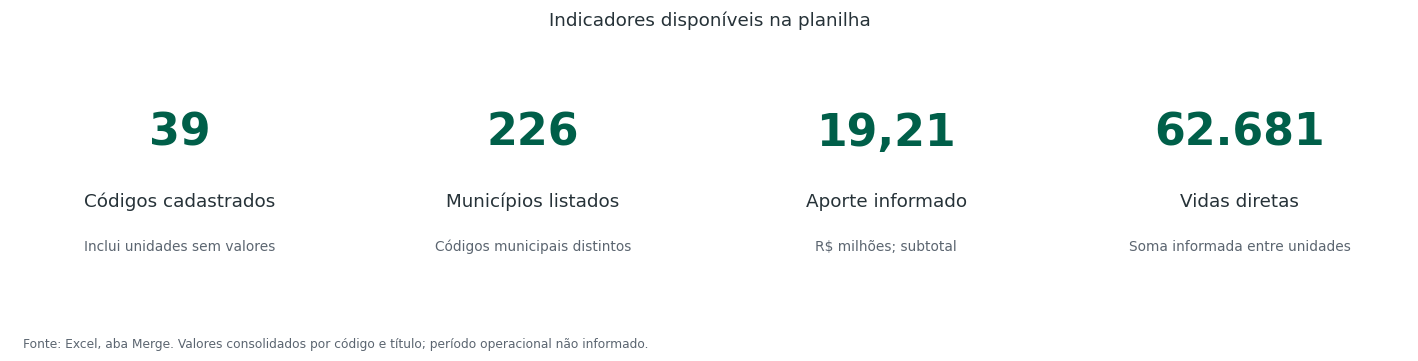

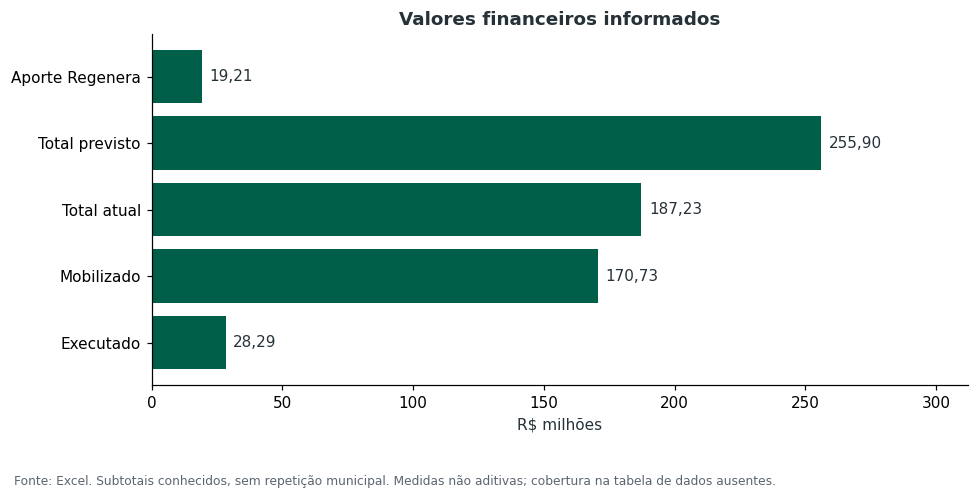

In [7]:
indicadores = pd.DataFrame([
    ("Códigos cadastrados na análise", unidades_analise["Codigo"].nunique(), "códigos", "Inclui registros sem valores e organizações intermediárias."),
    ("Unidades com dados quantitativos", int(unidades_analise["tem_dados_quantitativos"].sum()), "unidades", "Código + título; PRJ-019 preservado em dois subprojetos."),
    ("Municípios com projeto listado", len(codigos_listados), "municípios", "Vínculos informados; sem distribuição municipal de valores."),
    ("Aporte Regenera informado", unidades_analise["ValorAporteRegenera"].sum(min_count=1), "R$", "Subtotal conhecido."),
    ("Valor total previsto", unidades_analise["ValorTotalPrevisto"].sum(min_count=1), "R$", "Subtotal conhecido."),
    ("Valor total atual", unidades_analise["ValorTotalActual"].sum(min_count=1), "R$", "Subtotal conhecido."),
    ("Valor mobilizado", unidades_analise["ValorMobilizado"].sum(min_count=1), "R$", "Subtotal conhecido."),
    ("Valor executado", unidades_analise["ValorEjecutado"].sum(min_count=1), "R$", "Execução dos projetos; não identifica desembolso do fundo."),
    ("Vidas diretas informadas", unidades_analise["VidasDiretas"].sum(min_count=1), "pessoas", "Soma entre unidades; possíveis sobreposições de pessoas."),
    ("Vidas indiretas informadas", unidades_analise["VidasIndiretas"].sum(min_count=1), "pessoas", "Soma entre unidades; cobertura incompleta.")
], columns=["indicador", "valor", "unidade", "observação"])
tabela("indicadores_gerais", indicadores)
tabela("referencia_indicadores_2025", pd.DataFrame([
    ("Projetos aprovados", 21, "projetos", "21", "25"),
    ("Organizações intermediárias", 2, "organizações", "2", "25"),
    ("Cidades com projetos e pessoas beneficiadas", 110, "cidades", "Mais de 110", "25"),
    ("Valor deliberado", 15e6, "R$", "R$ 15 milhões", "25 e 51"),
    ("Valor desembolsado", 11e6, "R$", "R$ 11 milhões", "25 e 51"),
    ("Valor potencial dos projetos", 409e6, "R$", "R$ 409 milhões", "25 e 51"),
    ("Alavancagem atual", 18.88, "vezes", "18,88x", "25 e 51"),
    ("Alavancagem projetada", 27.7, "vezes", "27,7x", "25 e 51"),
    ("Vidas alcançadas diretamente", 85265, "pessoas", "85.265", "25"),
    ("Vidas alcançadas da rede pública de ensino", 770000, "pessoas", "770.000", "25"),
    ("Capital financeiro mobilizado pelo fundo", 40.5e6, "R$", "R$ 40,5 milhões", "51")
], columns=["indicador", "valor_referencia", "unidade", "expressao_publicada", "paginas_pdf"]), mostrar=False)

fig, axs = plt.subplots(1, 4, figsize=(13, 3.2))
cartoes = [("Códigos cadastrados", unidades_analise["Codigo"].nunique(), "Inclui unidades sem valores"),
           ("Municípios listados", len(codigos_listados), "Códigos municipais distintos"),
           ("Aporte informado", unidades_analise["ValorAporteRegenera"].sum(min_count=1) / 1e6, "R$ milhões; subtotal"),
           ("Vidas diretas", unidades_analise["VidasDiretas"].sum(min_count=1), "Soma informada entre unidades")]
for i, (ax, (rotulo, valor, unidade)) in enumerate(zip(axs, cartoes)):
    ax.set_axis_off()
    ax.text(0.5, 0.69, numero_pt(valor, 2 if i == 2 else 0), ha="center", fontsize=29, weight="bold", color=VERDE)
    ax.text(0.5, 0.43, rotulo, ha="center", fontsize=12)
    ax.text(0.5, 0.24, unidade, ha="center", fontsize=9, color=CINZA)
fig.suptitle("Indicadores disponíveis na planilha")
salvar_figura(fig, "01_indicadores_planilha", "Fonte: Excel, aba Merge. Valores consolidados por código e título; período operacional não informado.")

rotulos_fin = {"ValorAporteRegenera": "Aporte Regenera", "ValorTotalPrevisto": "Total previsto",
               "ValorTotalActual": "Total atual", "ValorMobilizado": "Mobilizado", "ValorEjecutado": "Executado"}
totais_fin = unidades_analise[CAMPOS_FINANCEIROS].sum(min_count=1).dropna()
fig, ax = plt.subplots(figsize=(9, 4.8))
barras = ax.barh([rotulos_fin[c] for c in totais_fin.index], totais_fin / 1e6, color=VERDE)
ax.bar_label(barras, labels=[numero_pt(v / 1e6, 2) for v in totais_fin], padding=5)
ax.set_xlim(0, max(totais_fin.max() / 1e6 * 1.22, 1))
ax.invert_yaxis()
ax.set_xlabel("R$ milhões")
ax.set_title("Valores financeiros informados")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, p: numero_pt(x)))
salvar_figura(fig, "02_valores_financeiros", "Fonte: Excel. Subtotais conhecidos, sem repetição municipal. Medidas não aditivas; cobertura na tabela de dados ausentes.")


### Alavancagem

A página 25 define o múltiplo como valor total alavancado dividido pelo valor deliberado. A planilha tem `ValorMobilizado`, `ValorTotalPrevisto` e `ValorAporteRegenera`, mas não documenta uma equivalência completa com essas definições. As razões abaixo são **indicativas** e usam apenas pares com numerador e denominador preenchidos. O agregado é a razão das somas, não a média dos múltiplos individuais.

Nas razões individuais, aportes iguais a zero deixam o resultado vazio. Registros com aporte zero permanecem na razão agregada se o par de valores estiver preenchido. Valores mobilizados por subprojetos podem precisar de revisão quanto à atribuição do aporte do projeto principal.


,razão_indicativa,unidades_pareadas,soma_numerador,soma_aportes_pareados,múltiplo
0,Mobilizado / aporte,23,1.707264e+08,19209074.0,8.887798
1,Previsto / aporte,23,2.558976e+08,19209074.0,13.321702


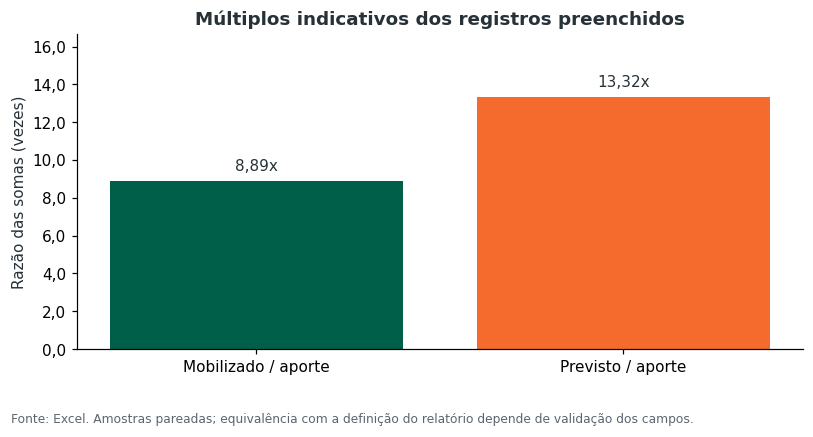

In [8]:
razoes = []
for coluna, rotulo in [("ValorMobilizado", "Mobilizado / aporte"), ("ValorTotalPrevisto", "Previsto / aporte")]:
    pares = unidades_analise[[coluna, "ValorAporteRegenera"]].dropna()
    numerador = pares[coluna].sum(min_count=1)
    denominador = pares["ValorAporteRegenera"].sum(min_count=1)
    razoes.append((rotulo, len(pares), numerador, denominador,
                   numerador / denominador if pd.notna(denominador) and denominador > 0 else np.nan))
alavancagem = pd.DataFrame(razoes, columns=["razão_indicativa", "unidades_pareadas", "soma_numerador", "soma_aportes_pareados", "múltiplo"])
tabela("alavancagem_indicativa", alavancagem)
unidades_analise["mobilizado_por_aporte"] = unidades_analise["ValorMobilizado"].div(unidades_analise["ValorAporteRegenera"].where(unidades_analise["ValorAporteRegenera"].gt(0)))
unidades_analise["previsto_por_aporte"] = unidades_analise["ValorTotalPrevisto"].div(unidades_analise["ValorAporteRegenera"].where(unidades_analise["ValorAporteRegenera"].gt(0)))
validas = alavancagem.dropna(subset=["múltiplo"])
if not validas.empty:
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    b = ax.bar(validas["razão_indicativa"], validas["múltiplo"], color=[VERDE, LARANJA][:len(validas)])
    ax.bar_label(b, labels=[numero_pt(v, 2) + "x" for v in validas["múltiplo"]], padding=5)
    ax.set_ylim(0, max(validas["múltiplo"].max() * 1.25, 1))
    ax.set_ylabel("Razão das somas (vezes)")
    ax.set_title("Múltiplos indicativos dos registros preenchidos")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: numero_pt(x, 1)))
    salvar_figura(fig, "03_alavancagem_indicativa", "Fonte: Excel. Amostras pareadas; equivalência com a definição do relatório depende de validação dos campos.")


## Aportes e códigos por eixo

Na rosca histórica, os valores publicados são arredondados e somam R$ 14,9 milhões, enquanto o total deliberado é apresentado como R$ 15 milhões. A rosca da planilha usa `ValorAporteRegenera`, inclusive para os registros sem eixo identificado. Os painéis têm universos e definições diferentes; não representam uma série temporal comparável.


,eixo,códigos_cadastrados,unidades,ValorAporteRegenera,ValorAporteRegenera__n,ValorAporteRegenera__ausentes,VidasDiretas,VidasDiretas__n,VidasDiretas__ausentes,VidasIndiretas,VidasIndiretas__n,VidasIndiretas__ausentes
0,Educação,8,8,3944375.0,5,3,38647.0,5,3,154445.0,4,4
1,Habitação,4,4,1450000.0,2,2,579.0,2,2,845.0,2,2
2,Apoio a negócios,3,3,3515000.0,2,1,12315.0,2,1,37794.0,2,1
3,Soluções urbanas,3,4,2170834.0,4,0,558.0,4,0,203030.0,4,0
4,Sem classificação,21,21,8128865.0,10,11,10582.0,10,11,49539.0,10,11


,eixo,aporte_aproximado_R$
0,Educação,3700000.0
1,Habitação,2900000.0
2,Apoio a negócios,5500000.0
3,Soluções urbanas,2800000.0


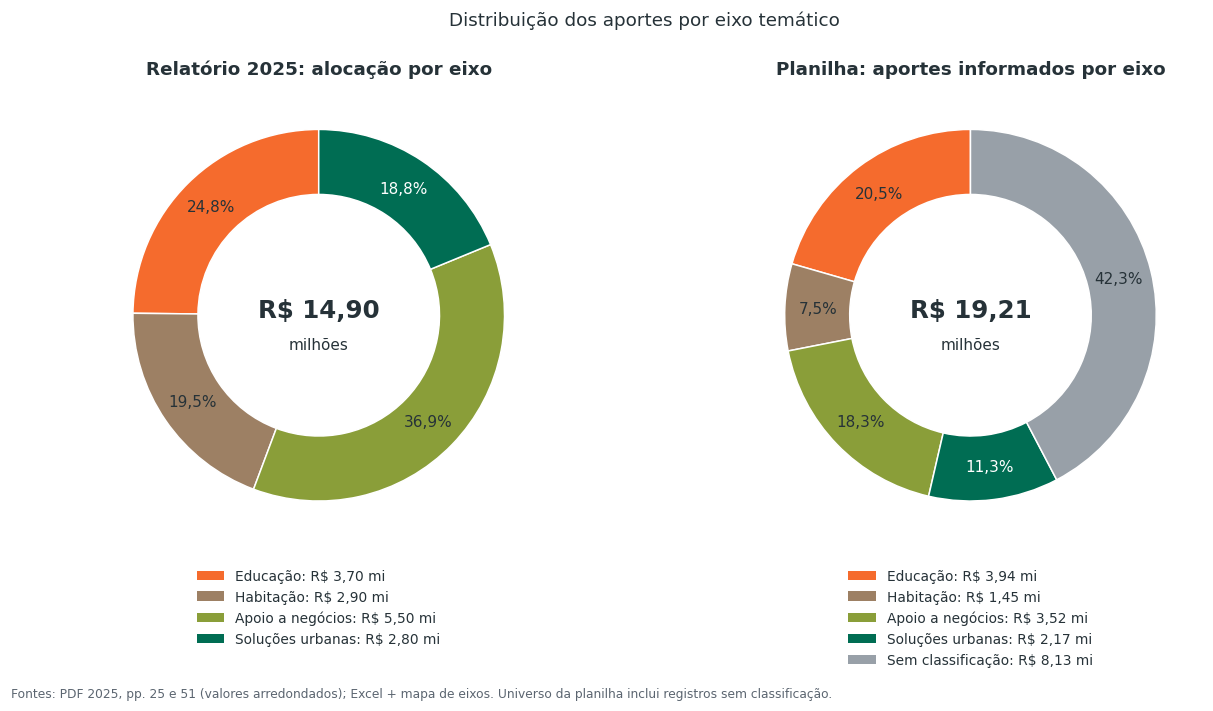

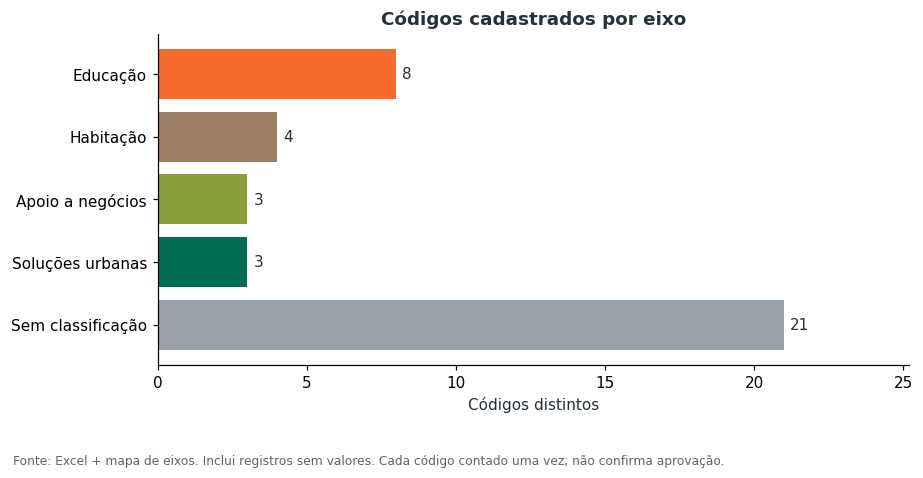

In [9]:
resumo_eixos = []
for eixo in ORDEM_EIXOS:
    dados = unidades_analise.loc[unidades_analise["eixo_usado"].eq(eixo)]
    if dados.empty:
        continue
    linha = {"eixo": eixo, "códigos_cadastrados": dados["Codigo"].nunique(), "unidades": len(dados)}
    for campo in ["ValorAporteRegenera", "VidasDiretas", "VidasIndiretas"]:
        linha[campo] = dados[campo].sum(min_count=1)
        linha[campo + "__n"] = dados[campo].notna().sum()
        linha[campo + "__ausentes"] = dados[campo].isna().sum()
    resumo_eixos.append(linha)
resumo_eixos = pd.DataFrame(resumo_eixos).set_index("eixo")
tabela("resumo_eixos", resumo_eixos.reset_index())
APORTES_PDF = pd.Series({"Educação": 3.7e6, "Habitação": 2.9e6, "Apoio a negócios": 5.5e6, "Soluções urbanas": 2.8e6})
tabela("referencia_aportes_2025", APORTES_PDF.rename_axis("eixo").rename("aporte_aproximado_R$").reset_index())

def rosca(ax, serie, titulo):
    serie = serie.dropna()
    serie = serie.loc[serie.gt(0)]
    if serie.empty:
        ax.set_axis_off()
        ax.text(0.5, 0.5, "Sem valores positivos disponíveis", transform=ax.transAxes, ha="center")
        return
    _, _, percentuais = ax.pie(serie, colors=[CORES_EIXOS[e] for e in serie.index], startangle=90,
           wedgeprops={"width": 0.35, "edgecolor": "white"},
           autopct=lambda p: numero_pt(p, 1) + "%", pctdistance=0.82, textprops={"fontsize": 10})
    for eixo, texto in zip(serie.index, percentuais):
        if eixo == "Soluções urbanas":
            texto.set_color("white")
    ax.text(0, 0.03, "R$ " + numero_pt(serie.sum() / 1e6, 2), ha="center", va="center", fontsize=16, weight="bold")
    ax.text(0, -0.18, "milhões", ha="center", fontsize=10)
    ax.set_title(titulo, fontsize=12)
    ax.legend([Patch(facecolor=CORES_EIXOS[e]) for e in serie.index],
              [e + ": R$ " + numero_pt(v / 1e6, 2) + " mi" for e, v in serie.items()],
              loc="upper center", bbox_to_anchor=(0.5, -0.02), frameon=False, fontsize=9)

fig, axs = plt.subplots(1, 2, figsize=(12, 6.5))
rosca(axs[0], APORTES_PDF, "Relatório 2025: alocação por eixo")
rosca(axs[1], resumo_eixos["ValorAporteRegenera"], "Planilha: aportes informados por eixo")
fig.suptitle("Distribuição dos aportes por eixo temático")
salvar_figura(fig, "04_aportes_eixos", "Fontes: PDF 2025, pp. 25 e 51 (valores arredondados); Excel + mapa de eixos. Universo da planilha inclui registros sem classificação.")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
b = ax.barh(resumo_eixos.index, resumo_eixos["códigos_cadastrados"], color=[CORES_EIXOS[e] for e in resumo_eixos.index])
ax.bar_label(b, padding=4)
ax.set_xlim(0, max(resumo_eixos["códigos_cadastrados"].max() * 1.2, 1))
ax.invert_yaxis()
ax.set_xlabel("Códigos distintos")
ax.set_title("Códigos cadastrados por eixo")
salvar_figura(fig, "05_codigos_eixos", "Fonte: Excel + mapa de eixos. Inclui registros sem valores. Cada código contado uma vez; não confirma aprovação.")


## Status dos projetos

As páginas 26–27 informam 3 finalizados, 9 em acompanhamento, 7 em implementação e 2 descontinuados, no total de 21 projetos. A figura abaixo reproduz essa referência histórica.

Para gerar um gráfico de status do cadastro, preencha `STATUS_ATUAIS` na configuração. O status deve ser verificado em uma fonte atual. Projetos sem preenchimento aparecem como `Sem informação`. A contagem continua sendo por código, sem transformar todos os registros em projetos aprovados.


,status,projetos_aprovados
0,Finalizado,3
1,Em acompanhamento,9
2,Em implementação,7
3,Descontinuado,2


Status atuais ausentes: o gráfico usa exclusivamente a referência de 2025.


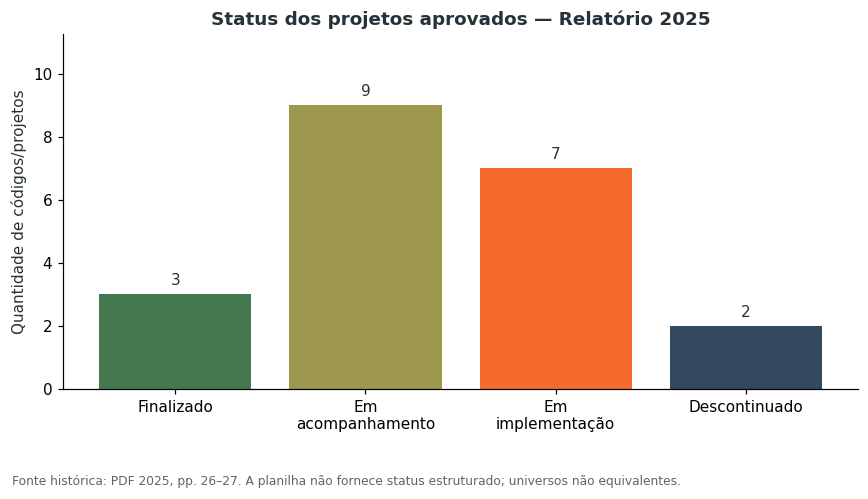

In [11]:
ORDEM_STATUS = ["Finalizado", "Em acompanhamento", "Em implementação", "Descontinuado", "Sem informação"]
STATUS_PDF = pd.Series({"Finalizado": 3, "Em acompanhamento": 9, "Em implementação": 7, "Descontinuado": 2})
tabela("referencia_status_2025", STATUS_PDF.rename_axis("status").rename("projetos_aprovados").reset_index())
for c, status in STATUS_ATUAIS.items():
    if c not in set(catalogo["Codigo"]) or status not in ORDEM_STATUS:
        raise ValueError(f"Status inválido: {c}: {status}")
status_cadastro = unidades_analise[["Codigo"]].drop_duplicates()
status_cadastro["status_informado"] = status_cadastro["Codigo"].map(STATUS_ATUAIS).fillna("Sem informação")
tabela("status_cadastro", status_cadastro, mostrar=False)

def barras_status(ax, serie, titulo):
    b = ax.bar(serie.index, serie.values, color=["#44784E", "#9D984E", LARANJA, "#34495E", "#98A0A8"][:len(serie)])
    ax.bar_label(b, padding=4)
    ax.set_ylim(0, max(serie.max() * 1.25, 1))
    ax.set_xticks(range(len(serie)), [s.replace(" ", "\n", 1) for s in serie.index])
    ax.set_ylabel("Quantidade de códigos/projetos")
    ax.set_title(titulo)

if STATUS_ATUAIS:
    fig, axs = plt.subplots(1, 2, figsize=(12, 5))
    barras_status(axs[0], STATUS_PDF, "Relatório 2025: 21 projetos aprovados")
    contagens = status_cadastro["status_informado"].value_counts().reindex(ORDEM_STATUS, fill_value=0)
    barras_status(axs[1], contagens, "Cadastro: status preenchidos pelo usuário")
else:
    fig, ax = plt.subplots(figsize=(8, 4.8))
    barras_status(ax, STATUS_PDF, "Status dos projetos aprovados — Relatório 2025")
    print("Status atuais ausentes: o gráfico usa exclusivamente a referência de 2025.")
salvar_figura(fig, "06_status_projetos", "Fonte histórica: PDF 2025, pp. 26–27. A planilha não fornece status estruturado; universos não equivalentes.")


## Vidas alcançadas por eixo

Os valores abaixo são os subtotais de `VidasDiretas` e `VidasIndiretas`. O número de unidades preenchidas e ausentes está em `resumo_eixos`. Ausência completa em um eixo produz uma célula vazia, e não zero.

O gráfico de bolhas usa área proporcional às vidas diretas informadas. Ele corresponde à organização por eixo da página 28, mas a coluna disponível não permite reproduzir a série de **vidas projetadas** do PDF. As séries direta e indireta também não são somadas como pessoas únicas.


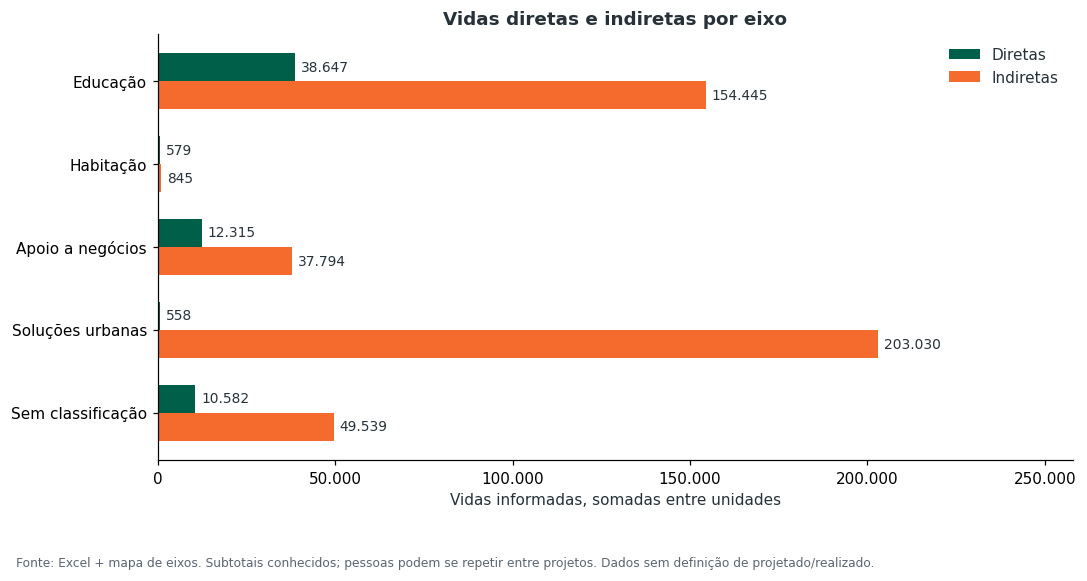

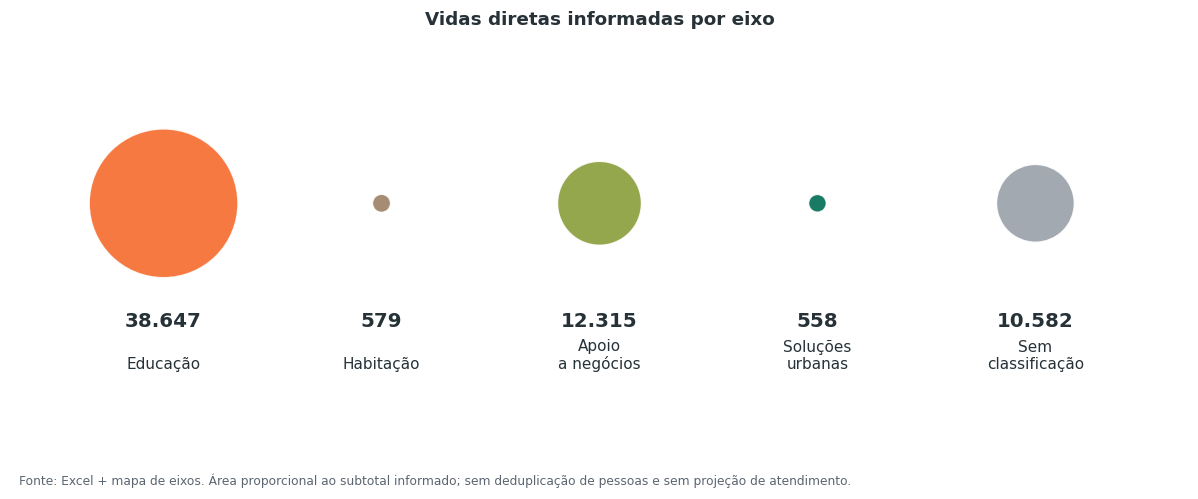

,eixo,vidas_projetadas_pdf
0,Educação,770000
1,Habitação,584
2,Apoio a negócios,32421
3,Soluções urbanas,1059


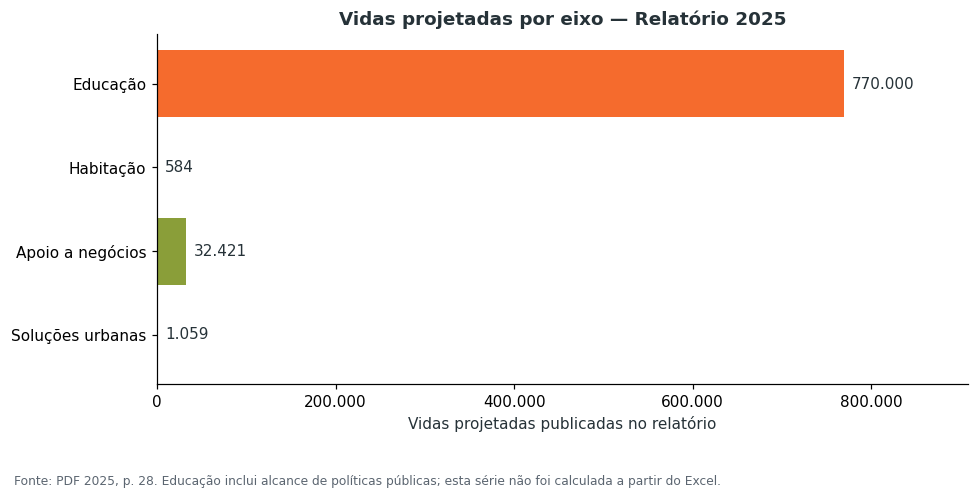

In [12]:
fig, ax = plt.subplots(figsize=(10, 5.6))
y = np.arange(len(resumo_eixos))
altura = 0.34
for campo, deslocamento, cor, rotulo in [("VidasDiretas", -altura/2, VERDE, "Diretas"),
                                       ("VidasIndiretas", altura/2, LARANJA, "Indiretas")]:
    valores = resumo_eixos[campo]
    b = ax.barh(y + deslocamento, valores, height=altura, color=cor, label=rotulo)
    ax.bar_label(b, labels=[numero_pt(v) if pd.notna(v) else "Sem informação" for v in valores], padding=4, fontsize=9)
ax.set_yticks(y, resumo_eixos.index)
ax.invert_yaxis()
maximo = resumo_eixos[CAMPOS_VIDAS].max().max()
ax.set_xlim(0, max(maximo * 1.27, 1))
ax.set_xlabel("Vidas informadas, somadas entre unidades")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, p: numero_pt(x)))
ax.set_title("Vidas diretas e indiretas por eixo")
ax.legend(frameon=False)
salvar_figura(fig, "07_vidas_eixos", "Fonte: Excel + mapa de eixos. Subtotais conhecidos; pessoas podem se repetir entre projetos. Dados sem definição de projetado/realizado.")

bolhas = resumo_eixos["VidasDiretas"].dropna()
if not bolhas.empty and bolhas.gt(0).any():
    fig, ax = plt.subplots(figsize=(11, 4.8))
    x = np.arange(len(bolhas))
    ax.scatter(x, np.ones(len(bolhas)), s=bolhas / bolhas.max() * 9500,
               c=[CORES_EIXOS[e] for e in bolhas.index], alpha=0.9, edgecolors="white", linewidths=1)
    for i, (eixo, valor) in enumerate(bolhas.items()):
        ax.text(i, 0.27, numero_pt(valor), ha="center", fontsize=13, weight="bold")
        ax.text(i, 0.02, eixo.replace(" ", "\n", 1), ha="center", fontsize=10)
    ax.set_xlim(-0.7, len(bolhas) - 0.3)
    ax.set_ylim(-0.35, 2.0)
    ax.set_axis_off()
    ax.set_title("Vidas diretas informadas por eixo")
    salvar_figura(fig, "08_bolhas_vidas_diretas", "Fonte: Excel + mapa de eixos. Área proporcional ao subtotal informado; sem deduplicação de pessoas e sem projeção de atendimento.")

VIDAS_PROJETADAS_PDF = pd.Series({"Educação": 770000, "Habitação": 584, "Apoio a negócios": 32421, "Soluções urbanas": 1059})
tabela("referencia_vidas_projetadas_2025", VIDAS_PROJETADAS_PDF.rename_axis("eixo").rename("vidas_projetadas_pdf").reset_index())
fig, ax = plt.subplots(figsize=(9, 4.8))
b = ax.barh(VIDAS_PROJETADAS_PDF.index, VIDAS_PROJETADAS_PDF.values, color=[CORES_EIXOS[e] for e in VIDAS_PROJETADAS_PDF.index])
ax.bar_label(b, labels=[numero_pt(v) for v in VIDAS_PROJETADAS_PDF], padding=5)
ax.set_xlim(0, VIDAS_PROJETADAS_PDF.max() * 1.18)
ax.invert_yaxis()
ax.set_xlabel("Vidas projetadas publicadas no relatório")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, p: numero_pt(x)))
ax.set_title("Vidas projetadas por eixo — Relatório 2025")
salvar_figura(fig, "09_referencia_vidas_projetadas_2025", "Fonte: PDF 2025, p. 28. Educação inclui alcance de políticas públicas; esta série não foi calculada a partir do Excel.")


## Estatísticas descritivas dos registros

As estatísticas usam uma observação por código e título, inclusive as unidades com dados ausentes. `n` conta valores preenchidos, `ausentes` conta valores não informados, e o desvio padrão é amostral (`ddof=1`). A soma não é calculada para razões de alavancagem, pois elas não são aditivas.


In [12]:
estatisticas = estatisticas_descritivas(unidades_analise, CAMPOS_QUANTITATIVOS + ["mobilizado_por_aporte", "previsto_por_aporte"])
estatisticas.loc[estatisticas["variável"].isin(["mobilizado_por_aporte", "previsto_por_aporte"]), "soma_conhecida"] = np.nan
tabela("descritivas_unidades", estatisticas)
descritivas_eixos = []
for eixo, dados in unidades_analise.groupby("eixo_usado", sort=False):
    e = estatisticas_descritivas(dados, CAMPOS_QUANTITATIVOS)
    e.insert(0, "eixo", eixo)
    descritivas_eixos.append(e)
tabela("descritivas_por_eixo", pd.concat(descritivas_eixos, ignore_index=True), mostrar=False)
tabela("unidades_consolidadas", unidades_analise, mostrar=False)


,variável,n,média,desvio_padrão,mínimo,Q1,mediana,Q3,máximo,ausentes,zeros,soma_conhecida
0,ValorAporteRegenera,23.0,8.351771e+05,7.771014e+05,0.000000,474300.000000,5.000000e+05,1.000000e+06,3.000250e+06,17,1,1.920907e+07
1,ValorTotalPrevisto,23.0,1.112598e+07,2.034772e+07,444375.000000,959246.500000,3.075000e+06,8.263293e+06,8.000000e+07,17,0,2.558976e+08
2,ValorTotalActual,21.0,8.915920e+06,1.900157e+07,0.000000,670834.000000,1.454252e+06,4.000000e+06,8.000000e+07,19,2,1.872343e+08
3,ValorMobilizado,23.0,7.422885e+06,1.728668e+07,97874.010000,522375.000000,1.159600e+06,3.125125e+06,7.000000e+07,17,0,1.707264e+08
4,ValorEjecutado,21.0,1.346989e+06,2.334560e+06,50723.640000,210203.630000,3.500000e+05,1.159600e+06,8.729863e+06,19,0,2.828678e+07
5,VidasDiretas,23.0,2.725261e+03,7.885724e+03,0.000000,84.000000,2.000000e+02,4.820000e+02,3.647200e+04,17,2,6.268100e+04
6,VidasIndiretas,22.0,2.025695e+04,5.099019e+04,0.000000,402.500000,1.330000e+03,5.137500e+03,2.000000e+05,18,3,4.456530e+05
7,mobilizado_por_aporte,22.0,6.968864e+00,1.473241e+01,0.617968,1.014875,2.159599e+00,6.467133e+00,7.000000e+01,18,0,NaN
8,previsto_por_aporte,22.0,1.293292e+01,2.059992e+01,1.000000,2.000000,4.336986e+00,9.673077e+00,7.864078e+01,18,0,NaN


## Abrangência municipal

A quantidade de vínculos é calculada por município e código de projeto distintos. Um mesmo código com dois subprojetos no mesmo município seria contado uma única vez. `Sem projeto listado` significa ausência de vínculo na base analisada, não uma afirmação sobre todas as atividades do RegeneraRS.

Os valores originais vazios de `Número de proyectos` na aba municipal são preservados. A coluna derivada `codigos_listados_na_analise` conta vínculos observados e pode ter zero, sem preencher os valores originais.


,grupo_territorial,municipios,populacao_media_somada,percentual_dos_municipios
0,Com projeto listado,226,9.872623e+06,45.472837
1,Sem projeto listado,271,1.338695e+06,54.527163


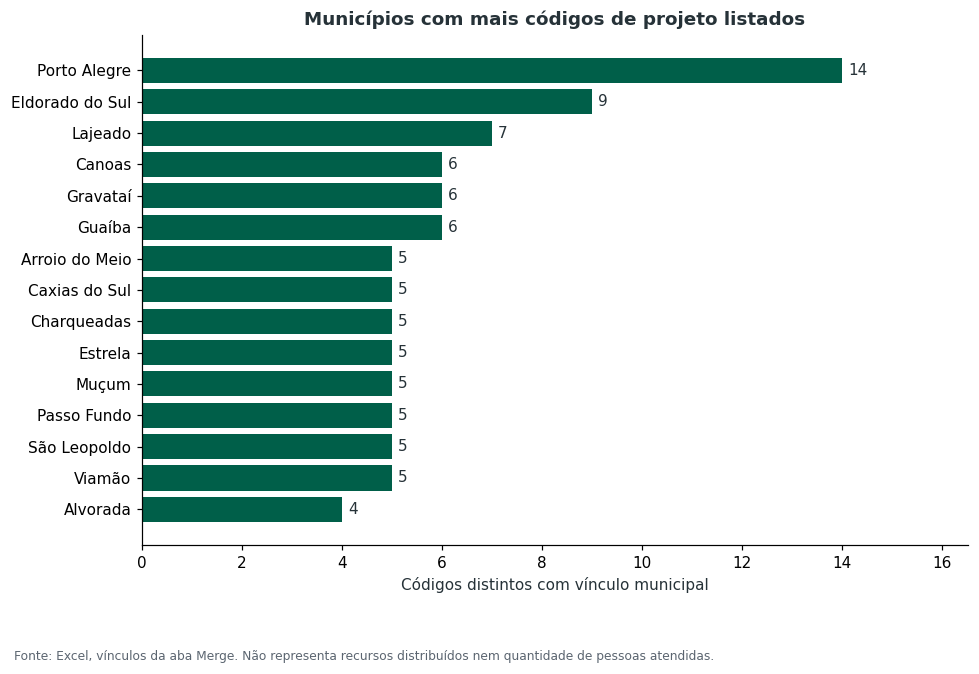

In [13]:
abrangencia = municipios.groupby("grupo_territorial", sort=False).agg(
    municipios=("municipality_code_7", "nunique"),
    populacao_media_somada=("Population__mean", lambda s: s.sum(min_count=1)))
abrangencia["percentual_dos_municipios"] = 100 * abrangencia["municipios"] / len(municipios)
tabela("abrangencia_municipal", abrangencia.reset_index())
tabela("vinculos_codigo_municipio", vinculos_analise.merge(municipios[["municipality_code_7", "Municipio"]], on="municipality_code_7", validate="many_to_one"), mostrar=False)
tabela("municipios_contexto", municipios, mostrar=False)

top = municipios.loc[municipios["com_projeto_listado"], ["Municipio", "codigos_listados_na_analise"]].sort_values(
    ["codigos_listados_na_analise", "Municipio"], ascending=[False, True]).head(15)
if not top.empty:
    fig, ax = plt.subplots(figsize=(9, 6.5))
    b = ax.barh(top["Municipio"], top["codigos_listados_na_analise"], color=VERDE)
    ax.bar_label(b, padding=4)
    ax.set_xlim(0, max(top["codigos_listados_na_analise"].max() * 1.18, 1))
    ax.invert_yaxis()
    ax.set_xlabel("Códigos distintos com vínculo municipal")
    ax.set_title("Municípios com mais códigos de projeto listados")
    salvar_figura(fig, "10_vinculos_municipais", "Fonte: Excel, vínculos da aba Merge. Não representa recursos distribuídos nem quantidade de pessoas atendidas.")


## Contexto fiscal e populacional dos municípios

As tabelas seguintes descrevem as **médias temporais municipais já existentes** no FINBRA/SICONFI. Não há dados anuais neste bloco que permitam reconstruir uma série ano a ano. Um município com `__count` menor que 3 possui menos observações para aquela média; essa cobertura é mostrada em uma tabela própria.

Os valores monetários são nominais conforme o arquivo de origem, sem correção pela inflação. `FiscalAutonomy` e `FPMDependency` são proporções e aparecem em porcentagem nos gráficos. Os valores originais são mantidos nas tabelas, inclusive os que excedem 1.

A comparação entre municípios com e sem projeto listado é descritiva. Ela não controla diferenças de porte, seleção territorial ou outras características e não estima impacto causal.


In [14]:
UNIDADES_FISCAIS = {"Population": "pessoas", "Rec Tributária": "R$", "Rec Correntes": "R$",
                   "Cota FPM": "R$", "FNAS": "R$", "ISSQN": "R$", "TaxRevenuePC": "R$/pessoa",
                   "FiscalAutonomy": "proporção", "FNAS_PC": "R$/pessoa", "FPMDependency": "proporção",
                   "ISSQN_PC": "R$/pessoa"}
fiscais = estatisticas_descritivas(municipios, CAMPOS_MEDIAS_FISCAIS)
fiscais["unidade"] = fiscais["variável"].str.replace("__mean", "", regex=False).map(UNIDADES_FISCAIS)
# A soma das proporções ou dos valores per capita não tem interpretação de total.
nao_aditivas = [f"{c}__mean" for c in ["TaxRevenuePC", "FiscalAutonomy", "FNAS_PC", "FPMDependency", "ISSQN_PC"]]
fiscais.loc[fiscais["variável"].isin(nao_aditivas), "soma_conhecida"] = np.nan
tabela("descritivas_fiscais_RS", fiscais)

por_grupo = []
for grupo, dados in municipios.groupby("grupo_territorial", sort=False):
    e = estatisticas_descritivas(dados, CAMPOS_MEDIAS_FISCAIS)
    e.loc[e["variável"].isin(nao_aditivas), "soma_conhecida"] = np.nan
    e.insert(0, "grupo", grupo)
    e["unidade"] = e["variável"].str.replace("__mean", "", regex=False).map(UNIDADES_FISCAIS)
    por_grupo.append(e)
tabela("descritivas_fiscais_grupos", pd.concat(por_grupo, ignore_index=True), mostrar=False)

cobertura_fiscal = []
for metrica in METRICAS_FISCAIS:
    contagens = municipios[f"{metrica}__count"]
    cobertura_fiscal.append((metrica, municipios[f"{metrica}__mean"].notna().sum(), contagens.eq(3).sum(),
                            contagens.eq(2).sum(), contagens.eq(1).sum(), contagens.eq(0).sum(), contagens.isna().sum()))
tabela("cobertura_temporal_fiscal", pd.DataFrame(cobertura_fiscal,
       columns=["métrica", "médias_preenchidas", "três_observações", "duas_observações", "uma_observação", "zero_observações", "contagem_ausente"]))


,variável,n,média,desvio_padrão,mínimo,Q1,mediana,Q3,máximo,ausentes,zeros,soma_conhecida,unidade
0,Population__mean,497.0,2.255799e+04,7.850970e+04,1.142000e+03,2.935333e+03,5.628333e+03,1.527667e+04,1.433689e+06,0,0,1.121132e+07,pessoas
1,Rec Tributária__mean,497.0,3.226441e+07,1.863716e+08,4.448068e+05,2.154831e+06,3.909169e+06,1.379447e+07,3.880679e+09,0,0,1.603541e+10,R$
2,Rec Correntes__mean,497.0,1.841143e+08,7.907055e+08,2.604849e+07,4.033225e+07,5.270490e+07,1.223185e+08,1.635509e+10,0,0,9.150479e+10,R$
3,Cota FPM__mean,497.0,5.777878e+07,6.391956e+07,2.569720e+07,3.353239e+07,3.353880e+07,5.593034e+07,9.926532e+08,0,0,2.871605e+10,R$
4,FNAS__mean,496.0,4.559319e+05,1.114853e+06,5.600000e+03,1.592196e+05,2.149852e+05,4.359083e+05,2.135593e+07,1,0,2.261422e+08,R$
5,ISSQN__mean,496.0,1.127729e+07,8.109623e+07,9.456546e+04,4.490296e+05,1.010677e+06,4.187939e+06,1.724127e+09,1,0,5.593538e+09,R$
6,TaxRevenuePC__mean,497.0,9.348073e+02,6.451107e+02,1.774327e+02,6.308276e+02,8.184296e+02,1.076503e+03,9.806455e+03,0,0,NaN,R$/pessoa
7,FiscalAutonomy__mean,497.0,9.357867e-02,6.238230e-02,1.331390e-02,5.158375e-02,7.412852e-02,1.163894e-01,4.581206e-01,0,0,NaN,proporção
8,FNAS_PC__mean,496.0,4.946934e+01,4.543537e+01,8.464329e-01,1.984001e+01,3.565765e+01,6.268842e+01,3.103279e+02,1,0,NaN,R$/pessoa
9,FPMDependency__mean,497.0,6.485750e-01,2.554287e-01,6.061178e-02,4.450780e-01,6.515318e-01,8.345700e-01,1.258862e+00,0,0,NaN,proporção


,métrica,médias_preenchidas,três_observações,duas_observações,uma_observação,zero_observações,contagem_ausente
0,Population,497,497,0,0,0,0
1,Rec Tributária,497,495,2,0,0,0
2,Rec Correntes,497,497,0,0,0,0
3,Cota FPM,497,494,2,1,0,0
4,FNAS,496,477,11,8,1,0
5,ISSQN,496,487,7,2,1,0
6,TaxRevenuePC,497,495,2,0,0,0
7,FiscalAutonomy,497,495,2,0,0,0
8,FNAS_PC,496,477,11,8,1,0
9,FPMDependency,497,494,2,1,0,0


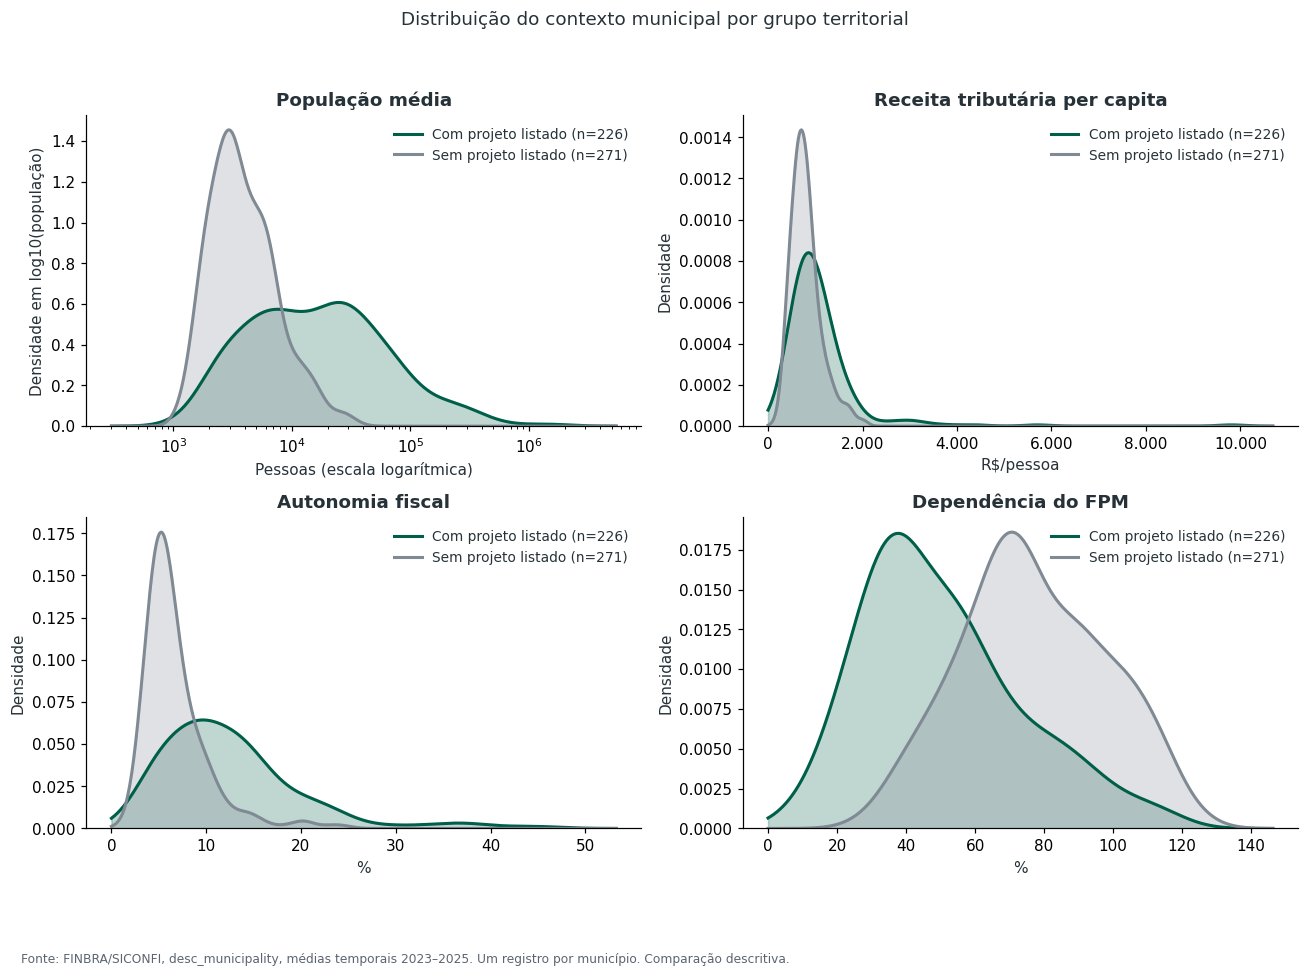

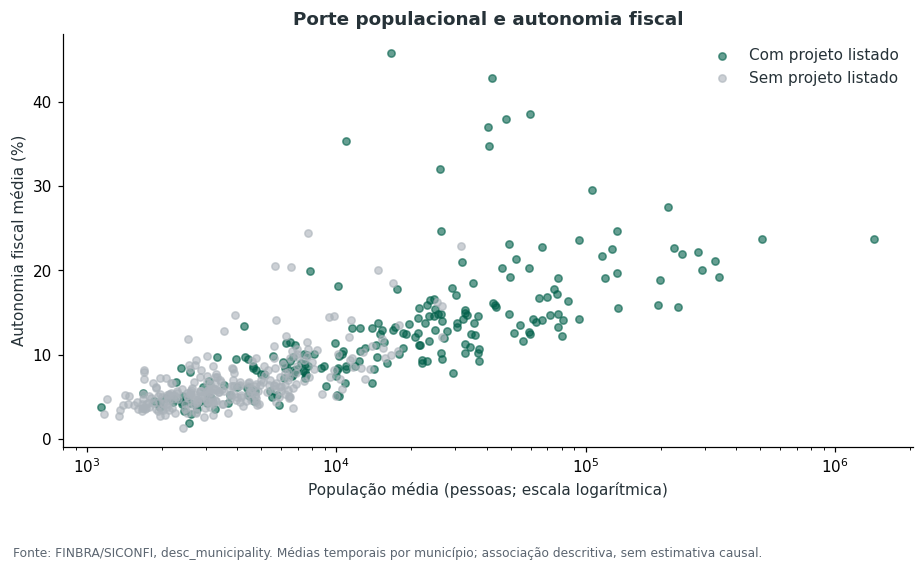

In [13]:
GRUPOS = ["Com projeto listado", "Sem projeto listado"]
painel_fiscal = [
    ("Population__mean", "População média", "Pessoas (escala logarítmica)", 1, True),
    ("TaxRevenuePC__mean", "Receita tributária per capita", "R$/pessoa", 1, False),
    ("FiscalAutonomy__mean", "Autonomia fiscal", "%", 100, False),
    ("FPMDependency__mean", "Dependência do FPM", "%", 100, False)
]

fig, axs = plt.subplots(2, 2, figsize=(12, 9))
for ax, (coluna, titulo, unidade, fator, log) in zip(axs.flat, painel_fiscal):
    series = [
        municipios.loc[municipios["grupo_territorial"].eq(g), coluna]
        .dropna().to_numpy(dtype=float) * fator
        for g in GRUPOS
    ]
    if any(len(s) < 2 or np.ptp(s) == 0 for s in series):
        ax.text(0.5, 0.5, "Dados insuficientes para estimar as curvas",
                transform=ax.transAxes, ha="center")
        ax.set_axis_off()
        continue

    # Para população, a KDE é estimada em log10 e exibida no eixo logarítmico.
    usar_log = log and all((s > 0).all() for s in series)
    valores = [np.log10(s) if usar_log else s for s in series]
    bandas = [s.std(ddof=1) * len(s) ** (-1 / 5) for s in valores]
    inferior = min(s.min() - 3 * h for s, h in zip(valores, bandas))
    superior = max(s.max() + 3 * h for s, h in zip(valores, bandas))
    if not usar_log and all((s >= 0).all() for s in series):
        inferior = max(0, inferior)
    grade = np.linspace(inferior, superior, 500)
    eixo_x = 10 ** grade if usar_log else grade

    # KDE gaussiana; cada grupo tem sua densidade normalizada separadamente.
    for s, h, grupo, cor in zip(valores, bandas, GRUPOS, [VERDE, "#808A94"]):
        distancia = (grade[:, None] - s[None, :]) / h
        densidade = np.exp(-0.5 * distancia ** 2).mean(axis=1) / (h * np.sqrt(2 * np.pi))
        ax.plot(eixo_x, densidade, color=cor, linewidth=2,
                label=f"{grupo} (n={len(s)})")
        ax.fill_between(eixo_x, densidade, color=cor, alpha=0.25)

    if usar_log:
        ax.set_xscale("log")
    else:
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, p: numero_pt(x)))
        if log:
            unidade = "Pessoas (escala linear: existem valores não positivos)"
    ax.set_xlabel(unidade)
    ax.set_ylabel("Densidade em log10(população)" if usar_log else "Densidade")
    ax.set_ylim(bottom=0)
    ax.set_title(titulo)
    ax.legend(frameon=False, fontsize=9)

fig.suptitle("Distribuição do contexto municipal por grupo territorial")
salvar_figura(
    fig, "11_contexto_fiscal_grupos",
    "Fonte: FINBRA/SICONFI, desc_municipality, médias temporais 2023–2025. Um registro por município. Comparação descritiva."
)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
for grupo, cor in zip(GRUPOS, [VERDE, "#AAB2B9"]):
    dados = municipios.loc[municipios["grupo_territorial"].eq(grupo)].dropna(
        subset=["Population__mean", "FiscalAutonomy__mean"]
    )
    dados = dados.loc[dados["Population__mean"].gt(0)]
    ax.scatter(dados["Population__mean"], dados["FiscalAutonomy__mean"] * 100,
               s=23, color=cor, alpha=0.6, label=grupo)
ax.set_xscale("log")
ax.set_xlabel("População média (pessoas; escala logarítmica)")
ax.set_ylabel("Autonomia fiscal média (%)")
ax.set_title("Porte populacional e autonomia fiscal")
ax.legend(frameon=False)
salvar_figura(
    fig, "12_populacao_autonomia",
    "Fonte: FINBRA/SICONFI, desc_municipality. Médias temporais por município; associação descritiva, sem estimativa causal."
)

## Tese de investimento e participação na mídia

Os 70% e 30% da página 13 são a composição desejada dos recursos por tese de investimento. Eles não são uma classificação observada na planilha. A figura de mídia reproduz a página 48: 11% para veículos de grande circulação, 44% para veículos regionais e trade e 45% para blogs e sites menores. São dados históricos, sem atualização pelo Excel.

Se houver uma classificação atual verificada, preencha `TESES_ATUAIS` com `Estruturantes e sistêmicos` ou `Inovadoras e comunitárias`. A alocação será calculada por aporte informado, incluindo `Sem classificação` no denominador, e exportada em uma figura separada.


,tese,meta_percentual
0,Estruturantes e sistêmicos,70
1,Inovadoras e comunitárias,30


,veículos,participacao_percentual
0,Grande circulação,11
1,Regionais e trade,44
2,Blogs e sites menores,45


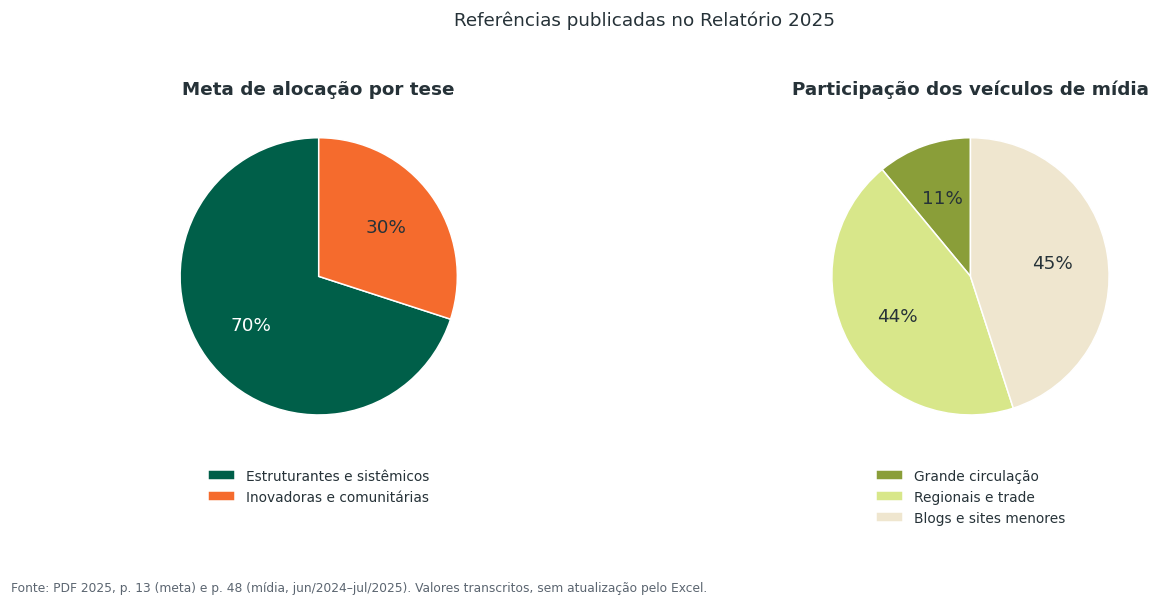

Sem classificação atual por tese: a proporção 70/30 permanece apenas como referência da meta.


In [14]:
TESE_PDF = pd.Series({"Estruturantes e sistêmicos": 70, "Inovadoras e comunitárias": 30})
MIDIA_PDF = pd.Series({"Grande circulação": 11, "Regionais e trade": 44, "Blogs e sites menores": 45})
tabela("referencia_tese_2025", TESE_PDF.rename_axis("tese").rename("meta_percentual").reset_index())
tabela("referencia_midia_2025", MIDIA_PDF.rename_axis("veículos").rename("participacao_percentual").reset_index())
tabela("referencia_indicadores_midia_2025", pd.DataFrame([
    ("Publicações", 357, "publicações", "357"),
    ("Equivalência em valor publicitário", 35.2e6, "R$", "R$ 35,2 milhões"),
    ("Alcance", 2.1e9, "alcance informado", "Mais de 2,1 bilhões"),
    ("Menções positivas", 100, "%", "100%")
], columns=["indicador", "valor_referencia", "unidade", "expressao_publicada"]), mostrar=False)

fig, axs = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, serie, cores, titulo in [(axs[0], TESE_PDF, [VERDE, LARANJA], "Meta de alocação por tese"),
                                (axs[1], MIDIA_PDF, ["#8A9E39", "#D8E78A", "#EFE6CF"], "Participação dos veículos de mídia")]:
    _, _, percentuais = ax.pie(serie.values, colors=cores, autopct=lambda p: numero_pt(p) + "%", startangle=90,
           wedgeprops={"edgecolor": "white"}, textprops={"fontsize": 12})
    for cor, texto in zip(cores, percentuais):
        if cor == VERDE:
            texto.set_color("white")
    ax.set_title(titulo)
    ax.legend(serie.index, loc="upper center", bbox_to_anchor=(0.5, -0.02), frameon=False, fontsize=9)
fig.suptitle("Referências publicadas no Relatório 2025")
salvar_figura(fig, "13_referencias_tese_midia_2025", "Fonte: PDF 2025, p. 13 (meta) e p. 48 (mídia, jun/2024–jul/2025). Valores transcritos, sem atualização pelo Excel.")

teses_validas = list(TESE_PDF.index) + ["Sem classificação"]
for c, tese in TESES_ATUAIS.items():
    if c not in set(catalogo["Codigo"]) or tese not in teses_validas:
        raise ValueError(f"Tese inválida: {c}: {tese}")
unidades_analise["tese_informada"] = unidades_analise["Codigo"].map(TESES_ATUAIS).fillna("Sem classificação")
if TESES_ATUAIS:
    aportes_tese = unidades_analise.groupby("tese_informada")["ValorAporteRegenera"].sum(min_count=1).dropna()
    tabela("aportes_por_tese", aportes_tese.rename_axis("tese").rename("aporte_informado_R$").reset_index())
    if aportes_tese.ge(0).all() and aportes_tese.sum() > 0:
        fig, ax = plt.subplots(figsize=(8, 4.5))
        percentuais = 100 * aportes_tese / aportes_tese.sum()
        b = ax.barh(percentuais.index, percentuais, color=VERDE)
        ax.bar_label(b, labels=[numero_pt(v, 1) + "%" for v in percentuais], padding=5)
        ax.set_xlim(0, 115)
        ax.set_xlabel("Participação nos aportes conhecidos (%)")
        ax.set_title("Aportes por tese preenchida pelo usuário")
        salvar_figura(fig, "14_aportes_tese_preenchida", "Fonte: Excel + TESES_ATUAIS preenchido pelo usuário. Sem classificação incluído no total; valores ausentes não imputados.")
else:
    print("Sem classificação atual por tese: a proporção 70/30 permanece apenas como referência da meta.")


## Entregas setoriais do relatório

Indicadores como escolas, casas e empregos aparecem no Excel em textos livres e podem misturar metas, resultados, datas e etapas. A atualização automática por busca de números nesses textos poderia somar valores com significados diferentes.

A tabela abaixo registra os números da página 28 e permite preenchimento verificado em `ENTREGAS_ATUAIS`. As expressões `mais de` são preservadas: o valor numérico é o limite publicado, não uma contagem exata. Não se somam indicadores com unidades diferentes.


In [15]:
ENTREGAS_ATUAIS = {}   # Exemplo: {"escolas_beneficiadas": 80}; use dados verificados para o mesmo indicador.
entregas = pd.DataFrame([
    ("escolas_beneficiadas", "Educação", "Escolas beneficiadas", 75, "75", "escolas"),
    ("municipios_escolas", "Educação", "Municípios das escolas beneficiadas", 22, "22", "municípios"),
    ("equipamentos", "Educação", "Equipamentos entregues", 400, "Mais de 400", "equipamentos"),
    ("acolhimento", "Educação", "Profissionais capacitados em acolhimento", 2500, "2.500", "profissionais"),
    ("professores_formados", "Educação", "Professores formados em práticas pedagógicas", 2000, "2.000", "professores"),
    ("planos_emergenciais", "Educação", "Escolas com planos emergenciais", 120, "120", "escolas"),
    ("gestores_formados", "Educação", "Gestores educacionais formados", 15, "15", "gestores"),
    ("negocios_apoiados", "Apoio a negócios", "Empreendedores/empresas apoiados", 781, "781", "empreendedores/empresas"),
    ("empregos", "Apoio a negócios", "Empregos impactados", 6900, "Mais de 6,9 mil", "empregos"),
    ("credito", "Apoio a negócios", "Crédito aprovado", 42e6, "R$ 42 milhões", "R$"),
    ("casas", "Habitação", "Casas sendo construídas", 169, "169", "casas"),
    ("melhorias_habitacionais", "Habitação", "Melhorias habitacionais entregues", 50, "50", "melhorias"),
    ("capacitacao_habitacao", "Habitação", "Profissionais capacitados", 500, "Mais de 500", "profissionais"),
    ("solucoes_urbanas", "Soluções urbanas", "Soluções urbanas em implementação", 19, "19", "soluções")
], columns=["indicador_id", "eixo", "indicador", "valor_referencia_2025", "expressao_publicada_2025", "unidade"])
if not set(ENTREGAS_ATUAIS).issubset(set(entregas["indicador_id"])):
    raise ValueError("Há indicador inexistente em ENTREGAS_ATUAIS.")
entregas["valor_atual_verificado"] = entregas["indicador_id"].map(ENTREGAS_ATUAIS)
tabela("entregas_setoriais", entregas)


,indicador_id,eixo,indicador,valor_referencia_2025,expressao_publicada_2025,unidade,valor_atual_verificado
0,escolas_beneficiadas,Educação,Escolas beneficiadas,75.0,75,escolas,NaN
1,municipios_escolas,Educação,Municípios das escolas beneficiadas,22.0,22,municípios,NaN
2,equipamentos,Educação,Equipamentos entregues,400.0,Mais de 400,equipamentos,NaN
3,acolhimento,Educação,Profissionais capacitados em acolhimento,2500.0,2.500,profissionais,NaN
4,professores_formados,Educação,Professores formados em práticas pedagógicas,2000.0,2.000,professores,NaN
5,planos_emergenciais,Educação,Escolas com planos emergenciais,120.0,120,escolas,NaN
6,gestores_formados,Educação,Gestores educacionais formados,15.0,15,gestores,NaN
7,negocios_apoiados,Apoio a negócios,Empreendedores/empresas apoiados,781.0,781,empreendedores/empresas,NaN
8,empregos,Apoio a negócios,Empregos impactados,6900.0,"Mais de 6,9 mil",empregos,NaN
9,credito,Apoio a negócios,Crédito aprovado,42000000.0,R$ 42 milhões,R$,NaN


,indicador_id,eixo,indicador,valor_referencia_2025,expressao_publicada_2025,unidade,valor_atual_verificado
0,escolas_beneficiadas,Educação,Escolas beneficiadas,75.0,75,escolas,NaN
1,municipios_escolas,Educação,Municípios das escolas beneficiadas,22.0,22,municípios,NaN
2,equipamentos,Educação,Equipamentos entregues,400.0,Mais de 400,equipamentos,NaN
3,acolhimento,Educação,Profissionais capacitados em acolhimento,2500.0,2.500,profissionais,NaN
4,professores_formados,Educação,Professores formados em práticas pedagógicas,2000.0,2.000,professores,NaN
5,planos_emergenciais,Educação,Escolas com planos emergenciais,120.0,120,escolas,NaN
6,gestores_formados,Educação,Gestores educacionais formados,15.0,15,gestores,NaN
7,negocios_apoiados,Apoio a negócios,Empreendedores/empresas apoiados,781.0,781,empreendedores/empresas,NaN
8,empregos,Apoio a negócios,Empregos impactados,6900.0,"Mais de 6,9 mil",empregos,NaN
9,credito,Apoio a negócios,Crédito aprovado,42000000.0,R$ 42 milhões,R$,NaN


## Exportação e verificação final

As tabelas numéricas são exportadas sem converter números em textos formatados. Cada CSV usa codificação UTF-8 e tabulação como separador. Células ausentes ficam vazias no CSV e no Excel. As figuras são exportadas em PNG a 300 dpi e PDF vetorial.

O arquivo `metodologia_execucao.json` registra a identificação da planilha, versões de bibliotecas, exclusões e configurações. Ele permite conferir qual base produziu os resultados. A execução cria arquivos com nomes constantes; ao executar novamente na mesma pasta, os resultados correspondentes são substituídos. O manifesto informa apenas as figuras produzidas na execução presente.


In [16]:
# Atualiza a tabela final com os campos derivados adicionados nas últimas seções.
tabela("unidades_consolidadas", unidades_analise, mostrar=False)
assert len(unidades) == len(base[CHAVE_UNIDADE].drop_duplicates())
assert vinculos_analise.duplicated(["Codigo", "municipality_code_7"]).sum() == 0
assert municipios["municipality_code_7"].nunique() == len(municipios)
assert resumo_eixos["códigos_cadastrados"].sum() == unidades_analise["Codigo"].nunique()
for c in ["ValorAporteRegenera", "VidasDiretas", "VidasIndiretas"]:
    assert np.isclose(resumo_eixos[c].sum(min_count=1), unidades_analise[c].sum(min_count=1), equal_nan=True)

for nome, dados in TABELAS.items():
    dados.to_csv(PASTA_SAIDA / (nome_seguro(nome) + ".csv"), sep="\t", encoding="utf-8", index=False, na_rep="")

abas_usadas = set()
with pd.ExcelWriter(PASTA_SAIDA / "RegeneraRS_tabelas_estatisticas.xlsx", engine="openpyxl") as escritor:
    for nome, dados in TABELAS.items():
        aba = nome_seguro(nome)[:31]
        original, i = aba, 1
        while aba in abas_usadas:
            aba = original[:27] + f"_{i}"
            i += 1
        abas_usadas.add(aba)
        dados.to_excel(escritor, sheet_name=aba, index=False, na_rep="")

metodologia = {
    "arquivo_entrada": arquivo.name, "sha256_entrada": sha256,
    "referencia_pdf": "Relatório Anual RegeneraRS, 07/2024–07/2025",
    "paginas_referencia": [13, 25, 26, 27, 28, 48, 51],
    "chave_consolidacao": CHAVE_UNIDADE,
    "codigos_excluidos": CODIGOS_EXCLUIR_ANALISE,
    "usar_eixos_sugeridos": USAR_EIXOS_SUGERIDOS, "ajustes_eixos": AJUSTES_EIXOS,
    "status_informados": STATUS_ATUAIS, "teses_informadas": TESES_ATUAIS,
    "entregas_informadas": ENTREGAS_ATUAIS,
    "valores_ausentes": "Mantidos; somas identificadas como subtotais conhecidos.",
    "fiscal": "desc_municipality; estatísticas temporais 2023–2025, uma linha por município.",
    "limitacoes": ["Período operacional da planilha não informado.",
                   "Vidas não deduplicadas entre unidades; não há repartição municipal de valores.",
                   "Possível sobreposição entre intermediárias e projetos depende de revisão do cadastro.",
                   "Campos financeiros não confirmam deliberação/desembolso ou definição de alavancagem do PDF."],
    "python": platform.python_version(), "pandas": pd.__version__,
    "numpy": np.__version__, "matplotlib": matplotlib.__version__,
    "figuras": FIGURAS, "tabelas": list(TABELAS)
}
(PASTA_SAIDA / "metodologia_execucao.json").write_text(json.dumps(metodologia, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Verificações concluídas. {len(FIGURAS)} figuras e {len(TABELAS)} tabelas geradas em {NOME_PASTA_RESULTADOS}.")
print("Arquivo de tabelas: RegeneraRS_tabelas_estatisticas.xlsx")


Verificações concluídas. 13 figuras e 21 tabelas geradas em resultados_regenerars.
Arquivo de tabelas: RegeneraRS_tabelas_estatisticas.xlsx


## Leitura dos resultados

Antes de usar os números em um relatório institucional, confira `cobertura_quantitativa`, `alertas_projetos`, `classificacao_eixos` e as possíveis sobreposições com organizações intermediárias. Registros com descrição e sem valores não são tratados como projetos de custo zero.

Os gráficos de 2025 documentam o relatório anterior. Os gráficos calculados a partir do Excel descrevem a base disponível, com as definições e limites indicados. Para atualizar status, teses de investimento, desembolsos do fundo e entregas setoriais, serão necessários dados estruturados e verificados desses indicadores.
